In [61]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mtick
import re

In [62]:
# Carga de microdatos oficiales DNRPA (con soporte de descarga automática desde datos.gob.ar)
import sys
import os
import glob

# Añadir directorio raíz para acceder al módulo de pipeline
for p in ['.', '..']:
    if os.path.abspath(p) not in sys.path:
        sys.path.insert(0, os.path.abspath(p))

data_dir = '../data' if os.path.exists('../data') else 'data'

try:
    from scripts.download_data import cargar_dataframe_dnrpa
    # Carga los CSVs de 2026; si no existen, los descarga automáticamente desde datos.gob.ar
    df = cargar_dataframe_dnrpa(years=[2026], dest_dir=data_dir, auto_download=True)
except Exception as e:
    print(f'[Aviso] Fallback a lectura directa: {e}')
    files = sorted(glob.glob(os.path.join(data_dir, 'dnrpa-inscripciones-iniciales-autos-2026*.csv')))
    df = pd.concat([pd.read_csv(f, low_memory=False) for f in files], ignore_index=True)

print(f'DataFrame cargado exitosamente: {len(df):,} registros y {len(df.columns)} variables.')

C:\Users\nico_\AppData\Local\Temp\ipykernel_27888\2681674396.py:6: DtypeWarning:

Columns (8,20) have mixed types. Specify dtype option on import or set low_memory=False.

C:\Users\nico_\AppData\Local\Temp\ipykernel_27888\2681674396.py:6: DtypeWarning:

Columns (20) have mixed types. Specify dtype option on import or set low_memory=False.

C:\Users\nico_\AppData\Local\Temp\ipykernel_27888\2681674396.py:6: DtypeWarning:

Columns (20) have mixed types. Specify dtype option on import or set low_memory=False.



In [63]:


# 1. DEFINICIÓN DE MARCAS CHINAS (Basado en los valores exactos de tu CSV)
CHINAS_AUTOS_Y_LIVIANOS = {
    'BAIC', 'BYD', 'HAVAL', 'CHERY', 'JETOUR', 'MG', 'CHANGAN', 
    'FOTON', 'JMC', 'DFSK', 'GREAT WALL', 'JAC', 'KYC', 'JMEV', 
    'SHINERAY', 'DOMY', 'KAIYI', 'GAC', 'MAXUS', 'ARCFOX', 'GEELY', 
    'FORTHING', 'XIAOMI', 'FONIX', 'RELY', 'LEAPMOTOR', 'SKYWELL', 
    'LYNK&CO', 'DEEPAL', 'EXEED', 'KARRY', 'BAW', 'MAEXTRO',
    'SMART', 'LOTUS', 'XEV','DONGFENG'
}

CHINAS_PESADOS = {
    'KAMA', 'DFAC DONGFENG', 'YUTONG', 
    'SHACMAN', 'SANY', 'HONGYAN', 'XCMG', 'KING LONG', 'YAXING', 
    'HUABANG', 'SINOTRUK', 'LIANGONG', 'AIMIX', 'LGMG', 'ZOOMLION', 
    'ZHONG TONG', 'CAMC', 'HUALU', 'TITAN VEHICLE', 'HOWO', 
    'XIAN HYZER', 'LANDKING', 'BEIBEN TRUCK', 'SITRAK', 'JULIN', 
    'SHIYUN', 'CLW', 'FAW', 'NUCTECH'
}

# Podés usar solo CHINAS_AUTOS_Y_LIVIANOS o unir ambas con (CHINAS_AUTOS_Y_LIVIANOS | CHINAS_PESADOS)
MARCAS_OBJETIVO = CHINAS_AUTOS_Y_LIVIANOS | CHINAS_PESADOS

def graficar_evolucion_chinos(df: pd.DataFrame, ponderar_condominio: bool = True):
    df_proc = df.copy()
    
    # 2. LIMPIEZA Y PREPARACIÓN DE FECHAS (Enero a Septiembre 2026)
    df_proc['tramite_fecha'] = pd.to_datetime(df_proc['tramite_fecha'], errors='coerce')
    df_proc = df_proc[
        (df_proc['tramite_fecha'] >= '2026-01-01') & 
        (df_proc['tramite_fecha'] <= '2026-09-30')
    ]
    df_proc['mes'] = df_proc['tramite_fecha'].dt.to_period('M').astype(str)
    
    # Normalización de marca y flag binario
    marca_norm = df_proc['automotor_marca_descripcion'].astype(str).str.strip().str.upper()
    df_proc['es_marca_china'] = marca_norm.isin(MARCAS_OBJETIVO).astype(int)
    
    # Ponderación por titularidad (evita contar 2 veces un mismo auto con dos titulares al 50%)
    if ponderar_condominio and 'titular_porcentaje_titularidad' in df_proc.columns:
        pct = pd.to_numeric(df_proc['titular_porcentaje_titularidad'], errors='coerce').fillna(100)
        # Si hay valores fuera de (0, 100], los forzamos a 100%
        pct = np.where((pct <= 0) | (pct > 100), 100, pct)
        df_proc['unidad'] = pct / 100.0
    else:
        df_proc['unidad'] = 1.0

    df_proc['unidad_china'] = df_proc['unidad'] * df_proc['es_marca_china']

    # 3. AGREGACIÓN MENSUAL
    resumen = (
        df_proc.groupby('mes', as_index=False)
        .agg(
            total_mes=('unidad', 'sum'),
            chinos_mes=('unidad_china', 'sum')
        )
        .sort_values('mes')
    )
    resumen['total_mes'] = resumen['total_mes'].round().astype(int)
    resumen['chinos_mes'] = resumen['chinos_mes'].round().astype(int)
    resumen['share_chino_pct'] = (resumen['chinos_mes'] / resumen['total_mes']) * 100

    # Etiquetas amigables para el eje X
    nombres_meses = {
        '2026-01': 'Ene 26', '2026-02': 'Feb 26', '2026-03': 'Mar 26',
        '2026-04': 'Abr 26', '2026-05': 'May 26', '2026-06': 'Jun 26',
        '2026-07': 'Jul 26', '2026-08': 'Ago 26', '2026-09': 'Sep 26'
    }
    resumen['mes_label'] = resumen['mes'].map(lambda x: nombres_meses.get(x, x))

    # 4. CONSTRUCCIÓN DEL GRÁFICO COMBINADO (BARRAS + LÍNEA)
    # 4. CONSTRUCCIÓN DEL GRÁFICO COMBINADO (SIN SUPERPOSICIÓN)
    fig, ax1 = plt.subplots(figsize=(12.5, 7), dpi=120)
    
    color_barras = '#D62828'   # Rojo intenso para volumen chino
    color_linea = '#003049'    # Azul oscuro para el % de Market Share
    
    max_unidades = resumen['chinos_mes'].max()
    max_share = resumen['share_chino_pct'].max()
    min_share = resumen['share_chino_pct'].min()

    # Eje 1: Barras (les damos aire arriba con * 1.55 para que ocupen los 2/3 inferiores)
    barras = ax1.bar(
        resumen['mes_label'], 
        resumen['chinos_mes'], 
        color=color_barras, 
        alpha=0.88, 
        width=0.55, 
        zorder=2,
        label='Inscripciones 0km Marcas Chinas (Unidades)'
    )
    ax1.set_ylabel('Cantidad de Autos Chinos Inscriptos (Unidades)', color=color_barras, fontsize=11, fontweight='bold')
    ax1.tick_params(axis='y', labelcolor=color_barras)
    ax1.set_ylim(0, max_unidades * 1.55)  # <-- Deja el tercio superior libre para la línea
    ax1.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
    ax1.grid(axis='y', linestyle='--', alpha=0.35, zorder=1)
    ax1.spines['top'].set_visible(False)

    # Etiquetas de CANTIDAD: Adentro de la barra (en blanco) para no competir arriba
    for bar in barras:
        altura = bar.get_height()
        texto_num = f'{int(altura):,}'.replace(',', '.')
        
        # Si la barra tiene suficiente altura, va adentro en blanco; si es muy baja, en la base
        if altura > (max_unidades * 0.12):
            ax1.annotate(
                texto_num,
                xy=(bar.get_x() + bar.get_width() / 2, altura),
                xytext=(0, -16),  # <-- Desplazamiento hacia ADENTRO de la barra
                textcoords="offset points",
                ha='center', va='top',
                fontsize=9.5, fontweight='bold', color='white',
                zorder=4
            )
        else:
            ax1.annotate(
                texto_num,
                xy=(bar.get_x() + bar.get_width() / 2, altura / 2),
                ha='center', va='center',
                fontsize=9, fontweight='bold', color='white',
                zorder=4
            )

    # Eje 2: Línea de Porcentaje (Desplazada hacia el carril superior para despegarse de las barras)
    ax2 = ax1.twinx()
    linea = ax2.plot(
        resumen['mes_label'], 
        resumen['share_chino_pct'], 
        color=color_linea, 
        marker='o', 
        linewidth=2.8, 
        markersize=8,
        zorder=5,
        label='% sobre el Total de Inscripciones del Mes'
    )
    ax2.set_ylabel('Participación sobre el Total del Mes (%)', color=color_linea, fontsize=11, fontweight='bold')
    ax2.tick_params(axis='y', labelcolor=color_linea)
    
    # Truco de escala dual: al ajustar el techo del eje 2 más cerca de max_share (1.18x),
    # la línea flota por encima del tope de las barras (que están al 1/1.55 = 64% de altura)
    ax2.set_ylim(0, max_share * 1.18)
    ax2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=1))
    ax2.spines['top'].set_visible(False)

    # Etiquetas de PORCENTAJE: Siempre arriba de la línea con recuadro opaco
    for i, txt in enumerate(resumen['share_chino_pct']):
        ax2.annotate(
            f'{txt:.1f}%',
            xy=(resumen['mes_label'].iloc[i], txt),
            xytext=(0, 10),  # <-- 10 puntos ARRIBA del nodo de la línea
            textcoords="offset points",
            ha='center', va='bottom',
            fontsize=9.5, fontweight='bold', color=color_linea,
            bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor=color_linea, alpha=0.95),
            zorder=6
        )

    plt.title(
        'Evolución de Inscripciones 0km de Marcas Chinas y Share Mensual (Ene - Sep 2026)',
        fontsize=13.5, fontweight='bold', pad=20
    )
    
    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax2.get_legend_handles_labels()
    ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left', frameon=True, facecolor='white', framealpha=0.95)

    plt.tight_layout()
    plt.show()

    # 5. IMPRIMIR TABLA RESUMEN CON ACUMULADO Y CRECIMIENTO MoM
    resumen['var_mensual_chinos_%'] = resumen['chinos_mes'].pct_change() * 100
    print("\n=== TABLA RESUMEN MENSUAL (ENE - SEP 2026) ===")
    print(resumen[['mes', 'total_mes', 'chinos_mes', 'share_chino_pct', 'var_mensual_chinos_%']].to_string(index=False))
    
    total_periodo = resumen['total_mes'].sum()
    chinos_periodo = resumen['chinos_mes'].sum()
    print(f"\nTOTAL ACUMULADO (9 MESES): {chinos_periodo:,} autos chinos sobre {total_periodo:,} totales ({chinos_periodo/total_periodo*100:.2f}%).".replace(',', '.'))
    
    return resumen

# Ejecución:


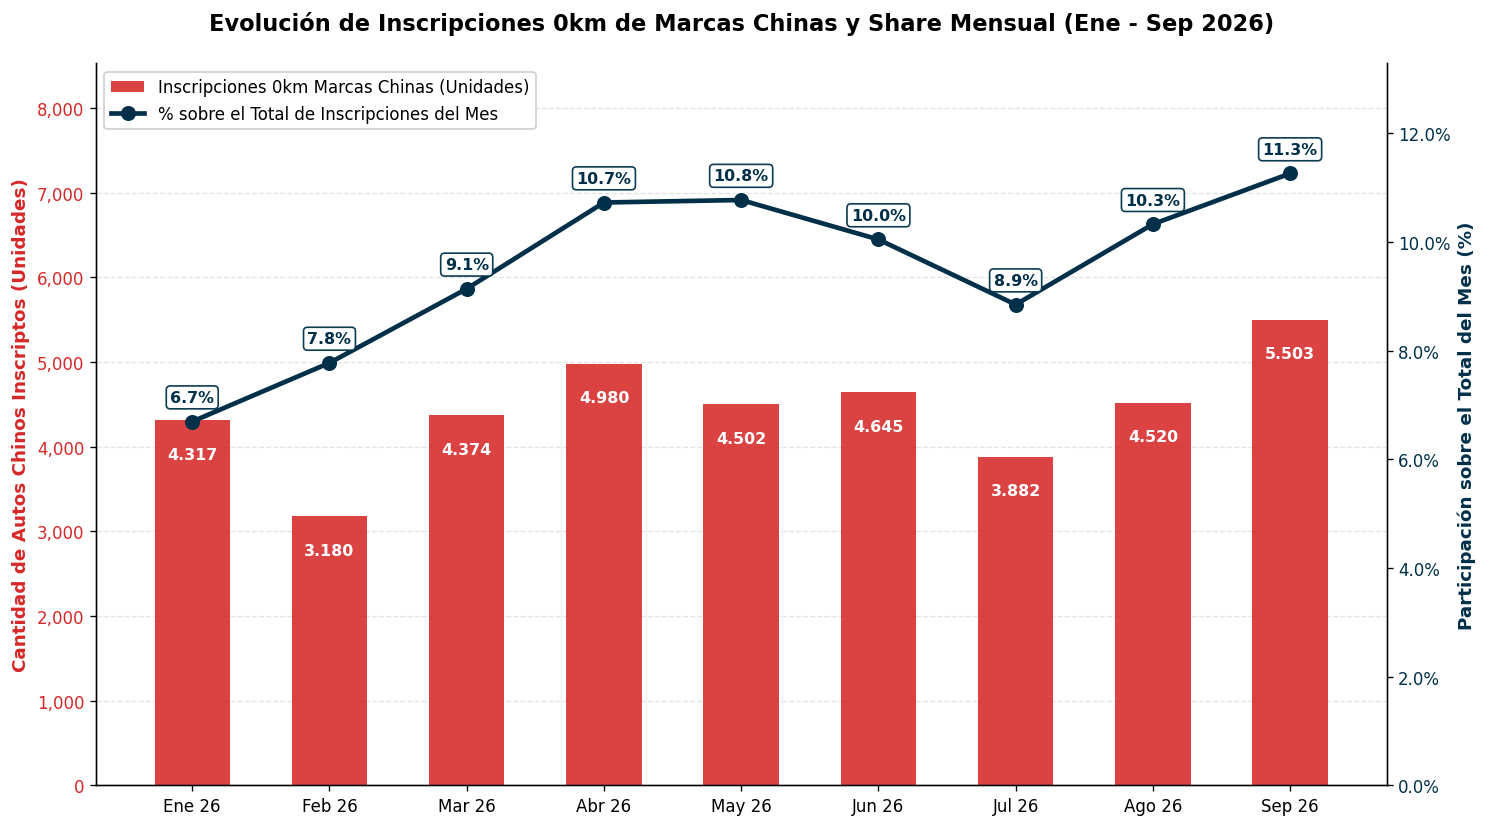


=== TABLA RESUMEN MENSUAL (ENE - SEP 2026) ===
    mes  total_mes  chinos_mes  share_chino_pct  var_mensual_chinos_%
2026-01      64464        4317         6.696761                   NaN
2026-02      40894        3180         7.776202            -26.337735
2026-03      47851        4374         9.140875             37.547170
2026-04      46416        4980        10.729059             13.854595
2026-05      41782        4502        10.774975             -9.598394
2026-06      46225        4645        10.048675              3.176366
2026-07      43863        3882         8.850284            -16.426265
2026-08      43756        4520        10.330012             16.434827
2026-09      48857        5503        11.263483             21.747788

TOTAL ACUMULADO (9 MESES): 39.903 autos chinos sobre 424.108 totales (9.41%).


In [64]:
tabla_mensual = graficar_evolucion_chinos(df, ponderar_condominio=True)

In [65]:
# sort by %

df['registro_seccional_provincia'].value_counts(normalize=True).sort_values(ascending=False).mul(100).round(2).to_frame(name='Porcentaje (%)').reset_index().rename(columns={'index': 'Provincia'})

,registro_seccional_provincia,Porcentaje (%)
0,Buenos Aires,27.65
1,Ciudad Autónoma de Buenos Aires,19.19
2,Córdoba,11.06
3,Santa Fe,9.47
4,Mendoza,4.39
5,Neuquén,3.01
6,Tucumán,2.60
7,Entre Ríos,2.38
8,Corrientes,2.15
9,Chubut,2.06


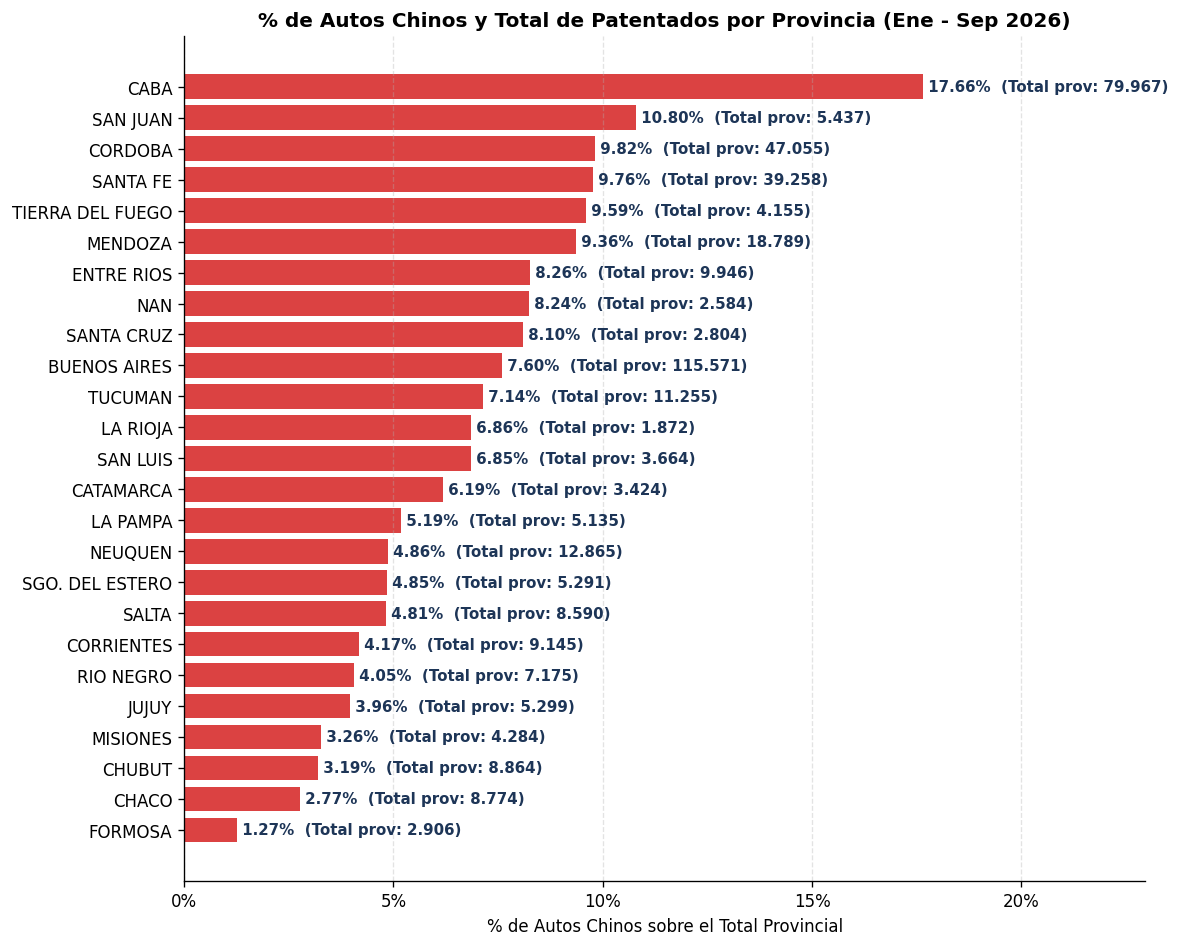

=== TOTAL DE PATENTADOS Y % DE CHINOS POR PROVINCIA ===
       provincia  total_patentados  pct_chinos
            CABA             79967       17.66
        SAN JUAN              5437       10.80
         CORDOBA             47055        9.82
        SANTA FE             39258        9.76
TIERRA DEL FUEGO              4155        9.59
         MENDOZA             18789        9.36
      ENTRE RIOS              9946        8.26
             NAN              2584        8.24
      SANTA CRUZ              2804        8.10
    BUENOS AIRES            115571        7.60
         TUCUMAN             11255        7.14
        LA RIOJA              1872        6.86
        SAN LUIS              3664        6.85
       CATAMARCA              3424        6.19
        LA PAMPA              5135        5.19
         NEUQUEN             12865        4.86
 SGO. DEL ESTERO              5291        4.85
           SALTA              8590        4.81
      CORRIENTES              9145        4.17
    

In [66]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

def resumen_simple_provincias(df: pd.DataFrame, ponderar_condominio: bool = True):
    df_proc = df.copy()
    
    # 1. Filtro de fechas (Ene - Sep 2026)
    df_proc['tramite_fecha'] = pd.to_datetime(df_proc['tramite_fecha'], errors='coerce')
    df_proc = df_proc[
        (df_proc['tramite_fecha'] >= '2026-01-01') & 
        (df_proc['tramite_fecha'] <= '2026-09-30')
    ]
    
    # 2. Normalizar nombres de provincia
    prov_clean = (
        df_proc['registro_seccional_provincia']
        .astype(str).str.strip().str.upper()
        .str.normalize('NFKD').str.encode('ascii', errors='ignore').str.decode('utf-8')
    )
    mapa_prov = {
        'CIUDAD AUTONOMA DE BS.AS.': 'CABA',
        'CIUDAD AUTONOMA DE BUENOS AIRES': 'CABA',
        'CAPITAL FEDERAL': 'CABA',
        'TIERRA DEL FUEGO, ANTARTIDA E ISLAS DEL ATLANTICO SUR': 'TIERRA DEL FUEGO',
        'SANTIAGO DEL ESTERO': 'SGO. DEL ESTERO'
    }
    df_proc['provincia'] = prov_clean.replace(mapa_prov)
    
    # 3. Identificar marca china y ponderar condominio
    marca_norm = df_proc['automotor_marca_descripcion'].astype(str).str.strip().str.upper()
    df_proc['es_marca_china'] = marca_norm.isin(MARCAS_OBJETIVO).astype(int)
    
    if ponderar_condominio and 'titular_porcentaje_titularidad' in df_proc.columns:
        pct = pd.to_numeric(df_proc['titular_porcentaje_titularidad'], errors='coerce').fillna(100)
        pct = np.where((pct <= 0) | (pct > 100), 100, pct)
        df_proc['unidad'] = pct / 100.0
    else:
        df_proc['unidad'] = 1.0
        
    df_proc['unidad_china'] = df_proc['unidad'] * df_proc['es_marca_china']
    
    # 4. Agrupar por provincia: solo Total y % Chinos
    resumen = (
        df_proc.groupby('provincia', as_index=False)
        .agg(
            total_patentados=('unidad', 'sum'),
            chinos=('unidad_china', 'sum')
        )
    )
    resumen['total_patentados'] = resumen['total_patentados'].round().astype(int)
    resumen['pct_chinos'] = (resumen['chinos'] / resumen['total_patentados'] * 100).round(2)
    
    # Dejamos únicamente las columnas pedidas, ordenadas por % de mayor a menor
    tabla_final = (
        resumen[['provincia', 'total_patentados', 'pct_chinos']]
        .sort_values('pct_chinos', ascending=False)
        .reset_index(drop=True)
    )
    
    # 5. Gráfico simple: Barras de % Chino con el Total de la provincia en la etiqueta
    fig, ax = plt.subplots(figsize=(10, 8), dpi=120)
    df_plot = tabla_final.iloc[::-1]
    
    bars = ax.barh(df_plot['provincia'], df_plot['pct_chinos'], color='#D62828', alpha=0.88)
    ax.set_title('% de Autos Chinos y Total de Patentados por Provincia (Ene - Sep 2026)', fontsize=12, fontweight='bold')
    ax.set_xlabel('% de Autos Chinos sobre el Total Provincial')
    ax.set_xlim(0, tabla_final['pct_chinos'].max() * 1.30)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(axis='x', linestyle='--', alpha=0.35)
    
    for bar, total_prov in zip(bars, df_plot['total_patentados']):
        w = bar.get_width()
        ax.annotate(
            f' {w:.2f}%  (Total prov: {total_prov:,})'.replace(',', '.'),
            xy=(w, bar.get_y() + bar.get_height() / 2),
            va='center', ha='left', fontsize=9, fontweight='bold', color='#1D3557'
        )
        
    plt.tight_layout()
    plt.show()
    
    print("=== TOTAL DE PATENTADOS Y % DE CHINOS POR PROVINCIA ===")
    print(tabla_final.to_string(index=False))
    return tabla_final

# Ejecución:
tabla_prov = resumen_simple_provincias(df)

In [67]:
import pandas as pd
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import urllib.request
import ssl
import json
import os

def crear_mapa_coropletico_argentina(tabla_prov: pd.DataFrame):
    df_mapa = tabla_prov.copy()
    
    # 1. Normalización de nombres de provincia
    prov_key = (
        df_mapa['provincia']
        .astype(str).str.strip().str.upper()
        .str.normalize('NFKD').str.encode('ascii', errors='ignore').str.decode('utf-8')
    )
    
    # Mapeo exacto contra la nomenclatura oficial del GeoJSON (IGN / Georef)
    mapa_nombres = {
        'BUENOS AIRES': 'Buenos Aires',
        'CABA': 'Ciudad Autónoma de Buenos Aires',
        'CIUDAD AUTONOMA DE BS.AS.': 'Ciudad Autónoma de Buenos Aires',
        'CIUDAD AUTONOMA DE BUENOS AIRES': 'Ciudad Autónoma de Buenos Aires',
        'CAPITAL FEDERAL': 'Ciudad Autónoma de Buenos Aires',
        'CATAMARCA': 'Catamarca',
        'CHACO': 'Chaco',
        'CHUBUT': 'Chubut',
        'CORDOBA': 'Córdoba',
        'CORRIENTES': 'Corrientes',
        'ENTRE RIOS': 'Entre Ríos',
        'FORMOSA': 'Formosa',
        'JUJUY': 'Jujuy',
        'LA PAMPA': 'La Pampa',
        'LA RIOJA': 'La Rioja',
        'MENDOZA': 'Mendoza',
        'MISIONES': 'Misiones',
        'NEUQUEN': 'Neuquén',
        'RIO NEGRO': 'Río Negro',
        'SALTA': 'Salta',
        'SAN JUAN': 'San Juan',
        'SAN LUIS': 'San Luis',
        'SANTA CRUZ': 'Santa Cruz',
        'SANTA FE': 'Santa Fe',
        'SGO. DEL ESTERO': 'Santiago del Estero',
        'SANTIAGO DEL ESTERO': 'Santiago del Estero',
        'TIERRA DEL FUEGO': 'Tierra del Fuego, Antártida e Islas del Atlántico Sur',
        'TIERRA DEL FUEGO, ANTARTIDA E ISLAS DEL ATLANTICO SUR': 'Tierra del Fuego, Antártida e Islas del Atlántico Sur',
        'TUCUMAN': 'Tucumán'
    }
    df_mapa['provincia_mapa'] = prov_key.map(mapa_nombres)
    
    # Si la columna 'chinos' no vino en tabla_prov, se calcula a partir del total y el %
    if 'chinos' not in df_mapa.columns:
        df_mapa['chinos'] = (df_mapa['total_patentados'] * df_mapa['pct_chinos'] / 100.0).round().astype(int)
    
    # Ranking provincial nacional de penetración (1 a 24)
    df_mapa['ranking'] = df_mapa['pct_chinos'].rank(ascending=False, method='min').astype(int)
    
    # Formateo de números para el cuadro flotante (tooltip con separadores de miles)
    df_mapa['total_formateado'] = df_mapa['total_patentados'].apply(lambda x: f"{int(x):,}".replace(",", "."))
    df_mapa['chinos_formateado'] = df_mapa['chinos'].apply(lambda x: f"{int(x):,}".replace(",", "."))
    df_mapa['pct_formateado'] = df_mapa['pct_chinos'].apply(lambda x: f"{x:.2f}%")
    
    # 2. Carga de GeoJSON (prioridad archivo local optimizado, con fallback a API Georef)
    geojson_data = None
    rutas_locales = [
        "../data/argentina-provincias.geojson",
        "data/argentina-provincias.geojson"
    ]
    for ruta in rutas_locales:
        if os.path.exists(ruta):
            try:
                with open(ruta, "r", encoding="utf-8") as f:
                    geojson_data = json.load(f)
                print(f"🗺️ GeoJSON cargado desde archivo local: {ruta}")
                break
            except Exception:
                pass
                
    if geojson_data is None:
        url_geojson = "https://apis.datos.gob.ar/georef/api/provincias.geojson"
        try:
            ctx = ssl.create_default_context()
            ctx.check_hostname = False
            ctx.verify_mode = ssl.CERT_NONE
            req = urllib.request.Request(url_geojson, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(req, timeout=15, context=ctx) as response:
                geojson_data = json.loads(response.read().decode('utf-8'))
                
            # Filtro del sector antártico e islas lejanas para encuadre óptimo
            for f in geojson_data.get('features', []):
                if 'Tierra del Fuego' in f.get('properties', {}).get('nombre', ''):
                    f['geometry']['coordinates'] = [
                        poly for poly in f['geometry']['coordinates']
                        if min([pt[1] for ring in poly for pt in ring]) >= -60.0
                        and max([pt[0] for ring in poly for pt in ring]) <= -53.0
                    ]
            print("🌐 GeoJSON descargado correctamente desde la API oficial de Georef.")
        except Exception as e:
            print(f"❌ Error al descargar el mapa: {e}")
            return None

    # 3. Separación de geometrías y datos: 23 Provincias vs CABA ampliada
    caba_nombre_oficial = "Ciudad Autónoma de Buenos Aires"
    
    features_arg = [f for f in geojson_data['features'] if f['properties']['nombre'] != caba_nombre_oficial]
    features_caba = [f for f in geojson_data['features'] if f['properties']['nombre'] == caba_nombre_oficial]
    
    geojson_arg = {"type": "FeatureCollection", "features": features_arg}
    geojson_caba = {"type": "FeatureCollection", "features": features_caba}
    
    df_arg = df_mapa[df_mapa['provincia_mapa'] != caba_nombre_oficial].copy()
    df_caba = df_mapa[df_mapa['provincia_mapa'] == caba_nombre_oficial].copy()
    
    # 4. Construcción de Subplots (Panel izquierdo: Provincias 60% | Panel derecho: Zoom CABA 40%)
    fig = make_subplots(
        rows=1, cols=2,
        column_widths=[0.60, 0.40],
        specs=[[{"type": "geo"}, {"type": "geo"}]],
        horizontal_spacing=0.06
    )
    
    hover_tmpl = (
        "<b style='font-size: 15px;'>%{customdata[0]}</b><br>"
        "<span style='color: #888;'>━━━━━━━━━━━━━━━━━━━━━━━━</span><br>"
        "🇨🇳 <b>Penetración Marcas Chinas:</b> <span style='color: #D62828; font-weight: bold;'>%{customdata[1]}</span> (Puesto #%{customdata[4]} de 24)<br>"
        "🚗 <b>Patentamientos Chinos:</b> %{customdata[2]} unidades<br>"
        "📊 <b>Total Inscripciones 0km:</b> %{customdata[3]} unidades"
        "<extra></extra>"
    )
    
    # Traza 1: Mapa General de Provincias (sin CABA para no tapar ni dificultar el clic)
    fig.add_trace(
        go.Choropleth(
            geojson=geojson_arg,
            locations=df_arg['provincia_mapa'],
            z=df_arg['pct_chinos'],
            featureidkey="properties.nombre",
            coloraxis="coloraxis",
            name="Provincias",
            customdata=df_arg[['provincia_mapa', 'pct_formateado', 'chinos_formateado', 'total_formateado', 'ranking']],
            hovertemplate=hover_tmpl,
            marker_line_width=0.9,
            marker_line_color="#333333"
        ),
        row=1, col=1
    )
    
    # Traza 2: Zoom Exclusivo de CABA (Fácilmente accesible con el cursor al costado)
    fig.add_trace(
        go.Choropleth(
            geojson=geojson_caba,
            locations=df_caba['provincia_mapa'],
            z=df_caba['pct_chinos'],
            featureidkey="properties.nombre",
            coloraxis="coloraxis",
            name="CABA (Zoom)",
            customdata=df_caba[['provincia_mapa', 'pct_formateado', 'chinos_formateado', 'total_formateado', 'ranking']],
            hovertemplate=hover_tmpl,
            marker_line_width=2.2,
            marker_line_color="#1D3557"
        ),
        row=1, col=2
    )
    
    # 5. Configuración de ejes geográficos (transparentes para integración limpia)
    fig.update_geos(
        row=1, col=1,
        fitbounds="locations",
        visible=False,
        bgcolor="rgba(0,0,0,0)"
    )
    fig.update_geos(
        row=1, col=2,
        fitbounds="locations",
        visible=False,
        bgcolor="rgba(0,0,0,0)"
    )
    
    # 6. Estética, tarjeta de ampliación CABA, línea conectora y barra de color
    fig.update_layout(
        title=dict(
            text="<b>Penetración de Autos Chinos 0km por Provincia (Ene - Sep 2026)</b><br><span style='font-size: 13px; color: #555;'>Mapa Nacional con ampliación exclusiva de Ciudad Autónoma de Buenos Aires (CABA)</span>",
            x=0.5,
            xanchor="center",
            font=dict(family="Arial, sans-serif", size=17, color="#1D3557")
        ),
        coloraxis=dict(
            colorscale="YlOrRd",
            colorbar=dict(
                title=dict(
                    text="<b>% Autos Chinos</b>",
                    font=dict(size=12, color="#1D3557")
                ),
                ticksuffix="%",
                thickness=16,
                len=0.36,
                orientation="h",
                x=0.81,
                y=0.10,
                xanchor="center",
                yanchor="bottom"
            )
        ),
        shapes=[
            # Tarjeta blanca para el panel de Zoom CABA
            dict(
                type="rect",
                xref="paper", yref="paper",
                x0=0.62, y0=0.22, x1=0.99, y1=0.92,
                line=dict(color="#1D3557", width=1.8),
                fillcolor="#FFFFFF",
                layer="below"
            ),
            # Barra superior de encabezado del panel CABA
            dict(
                type="rect",
                xref="paper", yref="paper",
                x0=0.62, y0=0.85, x1=0.99, y1=0.92,
                line=dict(width=0),
                fillcolor="#EBF2F7",
                layer="below"
            ),
            # Línea conectora punteada desde la ubicación costera de CABA hasta la tarjeta de zoom
            dict(
                type="line",
                xref="paper", yref="paper",
                x0=0.21, y0=0.54,
                x1=0.62, y1=0.59,
                line=dict(color="#457B9D", width=1.5, dash="dot")
            ),
            # Punto marcador (pin) en Buenos Aires
            dict(
                type="circle",
                xref="paper", yref="paper",
                x0=0.203, y0=0.533, x1=0.217, y1=0.547,
                fillcolor="#1D3557",
                line=dict(color="#FFFFFF", width=1.2)
            )
        ],
        annotations=[
            # Título de panel 1 (Provincias)
            dict(
                xref="paper", yref="paper",
                x=0.28, y=0.94,
                xanchor="center",
                text="<b>Mapa Nacional (23 Provincias)</b>",
                showarrow=False,
                font=dict(size=13.5, color="#1D3557", family="Arial, sans-serif")
            ),
            # Título de panel 2 (CABA)
            dict(
                xref="paper", yref="paper",
                x=0.805, y=0.885,
                xanchor="center",
                text="<b>🔍 Zoom: Ciudad Autónoma de Buenos Aires (CABA)</b>",
                showarrow=False,
                font=dict(size=12.5, color="#1D3557", family="Arial, sans-serif")
            ),
            # Indicación interactiva
            dict(
                xref="paper", yref="paper",
                x=0.805, y=0.25,
                xanchor="center",
                text="<i>💡 Pasa el cursor sobre la figura para ver las métricas</i>",
                showarrow=False,
                font=dict(size=11, color="#555555", family="Arial, sans-serif")
            )
        ],
        hoverlabel=dict(
            bgcolor="white",
            bordercolor="#1D3557",
            font_size=12.5,
            font_family="Arial, sans-serif"
        ),
        margin={"r": 20, "t": 85, "l": 20, "b": 30},
        paper_bgcolor="#F8F9FA",
        width=960,
        height=800,
        font=dict(family="Arial, sans-serif", size=12)
    )
    
    # Guardar en archivo HTML interactivo local
    nombre_archivo = "mapa_coropletico_autos_chinos_2026.html"
    fig.write_html(nombre_archivo)
    print(f"✅ ¡Mapa generado con éxito! Archivo guardado como '{nombre_archivo}'.")
    
    fig.show()
    return fig

# Ejecución:
fig_mapa = crear_mapa_coropletico_argentina(tabla_prov)


🗺️ GeoJSON cargado desde archivo local: ../data/argentina-provincias.geojson
✅ ¡Mapa generado con éxito! Archivo guardado como 'mapa_coropletico_autos_chinos_2026.html'.


=== DISTRIBUCIÓN GENERAL DE MOTORIZACIONES (ENE - SEP 2026) ===
                            tipo_motor  unidades  share_pct
                   1. ICE (Combustión)    379701      89.53
2. HEV / MHEV (Híbrido / Microhíbrido)     28871       6.81
          3. PHEV (Híbrido Enchufable)     11295       2.66
               4. BEV (100% Eléctrico)      4242       1.00

=== PARTICIPACIÓN TECNOLÓGICA SEGÚN ORIGEN DE MARCA (%) ===
tipo_motor                           1. ICE (Combustión)  2. HEV / MHEV (Híbrido / Microhíbrido)  3. PHEV (Híbrido Enchufable)  4. BEV (100% Eléctrico)
origen_marca                                                                                                                                           
Marcas Chinas                                      43.71                                   24.91                         20.82                    10.55
Marcas Tradicionales / Occidentales                94.29                                    4.93                       

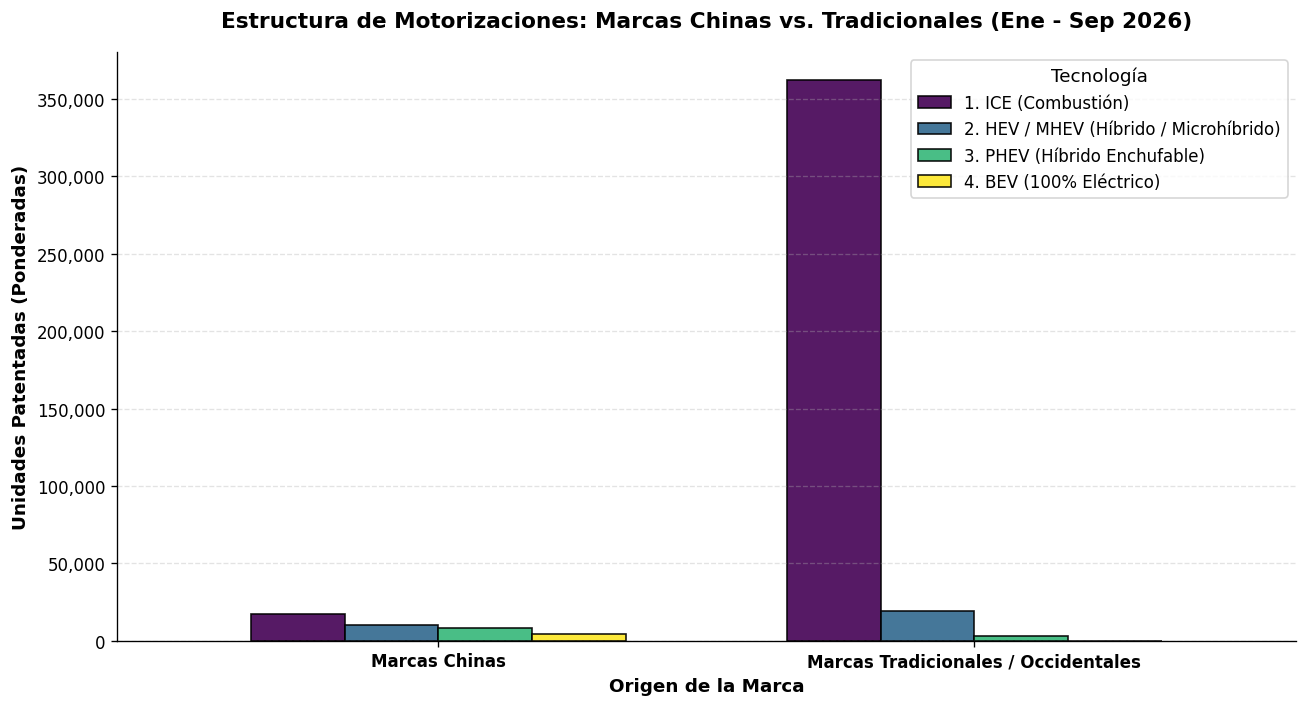

In [68]:
import re
def clasificar_motorizacion(modelo_desc: str) -> str:
    if not isinstance(modelo_desc, str):
        return '1. ICE (Combustión)'
    
    texto = modelo_desc.upper()
    
    # 1. 100% Eléctricos (BEV)
    if re.search(r'\b(EV|BEV|DOLPHIN|YUAN|ORA|ET5|E30X|ETERRON|EASY 3|TITO|TITA|SERO)\b', texto):
        return '4. BEV (100% Eléctrico)'
    
    # 2. Híbridos Enchufables (PHEV)
    if re.search(r'\b(PHEV|DM-I|DMI|SHARK|SONG PRO)\b', texto):
        return '3. PHEV (Híbrido Enchufable)'
    
    # 3. Híbridos Convencionales y Microhíbridos (HEV / MHEV)
    if re.search(r'\b(HEV|HYBRID|HIBRIDO|ECVT|MHEV|BJ30|E-POWER|MILD)\b', texto):
        return '2. HEV / MHEV (Híbrido / Microhíbrido)'
        
    return '1. ICE (Combustión)'

def analizar_motorizaciones_mercado(df: pd.DataFrame, ponderar_condominio: bool = True):
    df_proc = df.copy()
    
    # Filtro de fechas Ene - Sep 2026
    df_proc['tramite_fecha'] = pd.to_datetime(df_proc['tramite_fecha'], errors='coerce')
    df_proc = df_proc[
        (df_proc['tramite_fecha'] >= '2026-01-01') & 
        (df_proc['tramite_fecha'] <= '2026-09-30')
    ]
    df_proc['mes'] = df_proc['tramite_fecha'].dt.to_period('M').astype(str)
    
    # Ponderación por condominio
    if ponderar_condominio and 'titular_porcentaje_titularidad' in df_proc.columns:
        pct = pd.to_numeric(df_proc['titular_porcentaje_titularidad'], errors='coerce').fillna(100)
        pct = np.where((pct <= 0) | (pct > 100), 100, pct)
        df_proc['unidad'] = pct / 100.0
    else:
        df_proc['unidad'] = 1.0
        
    # Clasificación de motorización
    df_proc['tipo_motor'] = df_proc['automotor_modelo_descripcion'].apply(clasificar_motorizacion)
    
    # Bandera de marca china (usando el conjunto de marcas que definimos antes)
    marca_norm = df_proc['automotor_marca_descripcion'].astype(str).str.strip().str.upper()
    df_proc['es_china'] = marca_norm.isin(MARCAS_OBJETIVO).astype(int)
    df_proc['origen_marca'] = np.where(df_proc['es_china'] == 1, 'Marcas Chinas', 'Marcas Tradicionales / Occidentales')
    
    # 1. Tabla Resumen General por Tipo de Motor
    resumen_motor = (
        df_proc.groupby('tipo_motor', as_index=False)['unidad'].sum()
        .sort_values('tipo_motor')
    )
    total_gral = resumen_motor['unidad'].sum()
    resumen_motor['unidades'] = resumen_motor['unidad'].round().astype(int)
    resumen_motor['share_pct'] = (resumen_motor['unidades'] / total_gral * 100).round(2)
    
    # 2. Cruce: ¿Quién lidera la electrificación (Chinas vs Tradicionales)?
    cruce_origen_motor = pd.crosstab(
        df_proc['origen_marca'], 
        df_proc['tipo_motor'], 
        values=df_proc['unidad'], 
        aggfunc='sum', 
        normalize='index'
    ) * 100
    
    print("=== DISTRIBUCIÓN GENERAL DE MOTORIZACIONES (ENE - SEP 2026) ===")
    print(resumen_motor[['tipo_motor', 'unidades', 'share_pct']].to_string(index=False))
    
    print("\n=== PARTICIPACIÓN TECNOLÓGICA SEGÚN ORIGEN DE MARCA (%) ===")
    print(cruce_origen_motor.round(2).to_string())
    
    # 3. Gráfico de Barras Agrupadas: Motorización por Origen de Marca
    pivot_chart = pd.crosstab(
        df_proc['origen_marca'], 
        df_proc['tipo_motor'], 
        values=df_proc['unidad'], 
        aggfunc='sum'
    ).fillna(0)
    
    fig, ax = plt.subplots(figsize=(11, 6), dpi=120)
    pivot_chart.plot(kind='bar', ax=ax, colormap='viridis', width=0.7, edgecolor='black', alpha=0.9)
    
    ax.set_title('Estructura de Motorizaciones: Marcas Chinas vs. Tradicionales (Ene - Sep 2026)', fontsize=13, fontweight='bold', pad=15)
    ax.set_xlabel('Origen de la Marca', fontsize=11, fontweight='bold')
    ax.set_ylabel('Unidades Patentadas (Ponderadas)', fontsize=11, fontweight='bold')
    plt.xticks(rotation=0, fontweight='bold')
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(axis='y', linestyle='--', alpha=0.35)
    ax.legend(title='Tecnología', title_fontsize='11', loc='upper right', frameon=True, facecolor='white')
    
    plt.tight_layout()
    plt.show()
    
    return resumen_motor, cruce_origen_motor

# Ejecución:
resumen_motor, cruce_motor = analizar_motorizaciones_mercado(df)

In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

def radiografia_comprador(df: pd.DataFrame, ponderar_condominio: bool = True):
    df_proc = df.copy()
    
    # 1. Filtro temporal Ene - Sep 2026
    df_proc['tramite_fecha'] = pd.to_datetime(df_proc['tramite_fecha'], errors='coerce')
    df_proc = df_proc[
        (df_proc['tramite_fecha'] >= '2026-01-01') & 
        (df_proc['tramite_fecha'] <= '2026-09-30')
    ]
    
    # 2. Ponderación por condominio
    if ponderar_condominio and 'titular_porcentaje_titularidad' in df_proc.columns:
        pct = pd.to_numeric(df_proc['titular_porcentaje_titularidad'], errors='coerce').fillna(100)
        pct = np.where((pct <= 0) | (pct > 100), 100, pct)
        df_proc['unidad'] = pct / 100.0
    else:
        df_proc['unidad'] = 1.0
        
    # 3. Clasificación de Marca China y Motorización
    marca_norm = df_proc['automotor_marca_descripcion'].astype(str).str.strip().str.upper()
    df_proc['es_china'] = marca_norm.isin(MARCAS_OBJETIVO).astype(int)
    df_proc['origen_marca'] = np.where(df_proc['es_china'] == 1, 'Marcas Chinas', 'Marcas Tradicionales')
    
    # 4. Limpieza demográfica
    df_proc['titular_tipo_persona'] = df_proc['titular_tipo_persona'].astype(str).str.strip().str.capitalize()
    df_proc['titular_genero'] = df_proc['titular_genero'].astype(str).str.strip().str.capitalize()
    
    # Cálculo de edad (Año actual 2026)
    df_proc['titular_anio_nacimiento'] = pd.to_numeric(df_proc['titular_anio_nacimiento'], errors='coerce')
    df_proc['edad'] = 2026 - df_proc['titular_anio_nacimiento']
    # Filtrar valores ilógicos o personas jurídicas con edad cargada por error
    df_proc.loc[(df_proc['edad'] < 18) | (df_proc['edad'] > 100), 'edad'] = np.nan
    df_proc.loc[df_proc['titular_tipo_persona'] == 'Jurídica', 'edad'] = np.nan
    
    # Categorización por Grupos Etarios (Generaciones)
    def etiquetar_generacion(edad):
        if pd.isna(edad):
            return 'No Aplica / Jurídica'
        elif edad <= 30:
            return 'Gen Z (18-30 años)'
        elif edad <= 45:
            return 'Millennials (31-45 años)'
        elif edad <= 60:
            return 'Gen X (46-60 años)'
        else:
            return 'Baby Boomers+ (61+ años)'
            
    df_proc['generacion'] = df_proc['edad'].apply(etiquetar_generacion)
    
    print("=== 1. TIPO DE TITULAR (PERSONA FÍSICA VS JURÍDICA / FLOTAS) ===%s" % "")
    t_persona = pd.crosstab(
        df_proc['origen_marca'], 
        df_proc['titular_tipo_persona'], 
        values=df_proc['unidad'], 
        aggfunc='sum', 
        normalize='index'
    ) * 100
    print(t_persona.round(2).to_string())
    
    print("\n=== 2. DISTRIBUCIÓN POR GÉNERO (SOLO PERSONAS FÍSICAS) ===")
    df_fisicas = df_proc[df_proc['titular_tipo_persona'] == 'Física']
    t_genero = pd.crosstab(
        df_fisicas['origen_marca'], 
        df_fisicas['titular_genero'], 
        values=df_fisicas['unidad'], 
        aggfunc='sum', 
        normalize='index'
    ) * 100
    print(t_genero.round(2).to_string())
    
    print("\n=== 3. PERFIL ETARIO Y GENERACIONAL (%) ===")
    t_gen = pd.crosstab(
        df_proc['origen_marca'], 
        df_proc['generacion'], 
        values=df_proc['unidad'], 
        aggfunc='sum', 
        normalize='index'
    ) * 100
    print(t_gen.round(2).to_string())
    
    # Promedio de edad
    edad_promedio = df_proc.groupby('origen_marca').apply(lambda x: np.average(x['edad'].dropna(), weights=x.loc[x['edad'].notna(), 'unidad']))
    print(f"\nEdad Promedio del Titular:")
    print(edad_promedio.round(1))
    
    return df_proc

# Ejecución:
df_analisis = radiografia_comprador(df)

=== 1. TIPO DE TITULAR (PERSONA FÍSICA VS JURÍDICA / FLOTAS) ===
titular_tipo_persona  Física  Jurídica
origen_marca                          
Marcas Chinas          81.88     18.12
Marcas Tradicionales   78.45     21.55

=== 2. DISTRIBUCIÓN POR GÉNERO (SOLO PERSONAS FÍSICAS) ===
titular_genero        Femenino  Masculino  No identificado
origen_marca                                              
Marcas Chinas            37.11      62.89              0.0
Marcas Tradicionales     38.06      61.94              0.0

=== 3. PERFIL ETARIO Y GENERACIONAL (%) ===
generacion            Baby Boomers+ (61+ años)  Gen X (46-60 años)  Gen Z (18-30 años)  Millennials (31-45 años)  No Aplica / Jurídica
origen_marca                                                                                                                          
Marcas Chinas                            22.97               33.59                4.34                     20.93                 18.17
Marcas Tradicionales             

C:\Users\nico_\AppData\Local\Temp\ipykernel_27888\4199814996.py:87: DeprecationWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.




Edad Promedio del Titular:
origen_marca
Marcas Chinas           52.3
Marcas Tradicionales    50.1
dtype: float64


## 4. Ranking de Modelos Chinos Más Vendidos y Electrificación
¿Qué modelos específicos están impulsando el crecimiento de las marcas chinas en Argentina? Analizamos el volumen por modelo, su concentración sobre el total chino y el protagonismo de las motorizaciones híbridas (HEV/PHEV) y 100% eléctricas (EV).


C:\Users\nico_\AppData\Local\Temp\ipykernel_27888\2525228615.py:67: UserWarning:

Glyph 128267 (\N{BATTERY}) missing from current font.

C:\Users\nico_\AppData\Local\Temp\ipykernel_27888\2525228615.py:67: UserWarning:

Glyph 128268 (\N{ELECTRIC PLUG}) missing from current font.

C:\Users\nico_\AppData\Local\Temp\ipykernel_27888\2525228615.py:67: UserWarning:

Glyph 9981 (\N{FUEL PUMP}) missing from current font.

C:\Users\nico_\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:152: UserWarning:

Glyph 128267 (\N{BATTERY}) missing from current font.

C:\Users\nico_\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:152: UserWarning:

Glyph 128268 (\N{ELECTRIC PLUG}) missing from current font.

C:\Users\nico_\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:152: UserWarning:

Glyph 9981 (\N{FUEL PUMP}) missing from current font.



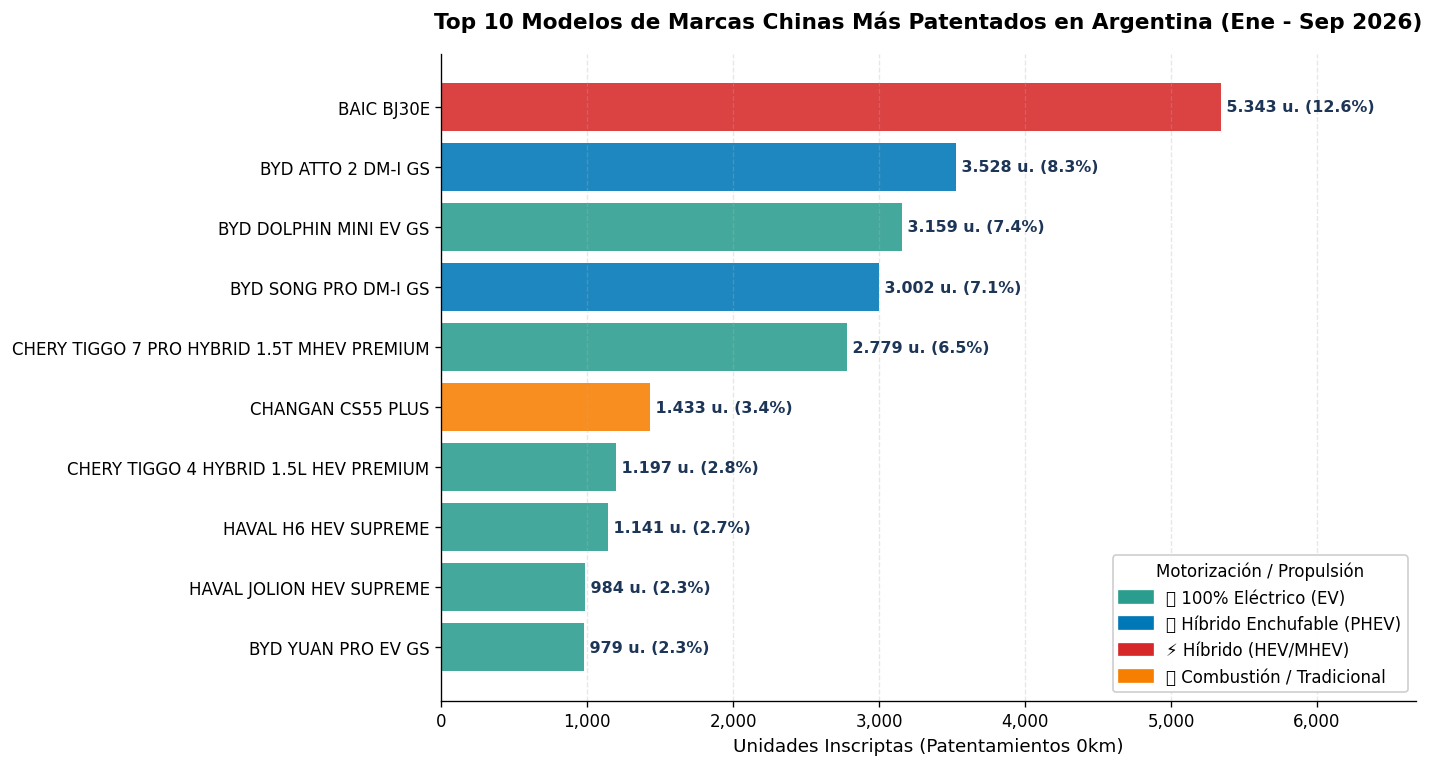


=== CONCENTRACIÓN DE MERCADO: TOP 10 MODELOS CHINOS ===
Los 10 modelos más vendidos suman 23.545 unidades. explicando el 55.4% de todos los autos chinos vendidos en el país.
                                  etiqueta  unidades  pct_sobre_chinos                  tecnologia
                                BAIC BJ30E      5343             12.58        ⚡ Híbrido (HEV/MHEV)
                        BYD ATTO 2 DM-I GS      3528              8.30 🔌 Híbrido Enchufable (PHEV)
                    BYD DOLPHIN MINI EV GS      3159              7.44       🔋 100% Eléctrico (EV)
                      BYD SONG PRO DM-I GS      3002              7.07 🔌 Híbrido Enchufable (PHEV)
CHERY TIGGO 7 PRO HYBRID 1.5T MHEV PREMIUM      2779              6.54       🔋 100% Eléctrico (EV)
                         CHANGAN CS55 PLUS      1433              3.37  ⛽ Combustión / Tradicional
     CHERY TIGGO 4 HYBRID 1.5L HEV PREMIUM      1197              2.82       🔋 100% Eléctrico (EV)
                      HAVAL H6 HE

In [70]:
# 4. RANKING DE MODELOS CHINOS MÁS PATENTADOS
def analizar_top_modelos_chinos(df: pd.DataFrame, top_n: int = 10):
    df_proc = df.copy()
    marca_norm = df_proc['automotor_marca_descripcion'].astype(str).str.strip().str.upper()
    df_chinos = df_proc[marca_norm.isin(MARCAS_OBJETIVO)].copy()
    
    total_chinos = len(df_chinos)
    
    top_modelos = (
        df_chinos.groupby(['automotor_marca_descripcion', 'automotor_modelo_descripcion'], as_index=False)
        .size()
        .rename(columns={'size': 'unidades'})
        .sort_values('unidades', ascending=False)
        .head(top_n)
        .reset_index(drop=True)
    )
    
    top_modelos['pct_sobre_chinos'] = (top_modelos['unidades'] / total_chinos * 100).round(2)
    top_modelos['etiqueta'] = top_modelos['automotor_marca_descripcion'] + ' ' + top_modelos['automotor_modelo_descripcion']
    
    # Identificar tecnología ecológica en el nombre del modelo
    def detectar_motor(nombre):
        n = str(nombre).upper()
        if 'EV' in n or 'ELÉCTRICO' in n or 'ELECTRICO' in n:
            return '🔋 100% Eléctrico (EV)'
        elif 'DM-I' in n or 'PHEV' in n or 'DMO' in n:
            return '🔌 Híbrido Enchufable (PHEV)'
        elif 'HYBRID' in n or 'HEV' in n or 'MHEV' in n or 'BJ30E' in n:
            return '⚡ Híbrido (HEV/MHEV)'
        else:
            return '⛽ Combustión / Tradicional'
            
    top_modelos['tecnologia'] = top_modelos['automotor_modelo_descripcion'].apply(detectar_motor)
    
    # Gráfico de barras horizontales
    fig, ax = plt.subplots(figsize=(12, 6.5), dpi=120)
    colores_motor = {
        '🔋 100% Eléctrico (EV)': '#2A9D8F',
        '🔌 Híbrido Enchufable (PHEV)': '#0077B6',
        '⚡ Híbrido (HEV/MHEV)': '#D62828',
        '⛽ Combustión / Tradicional': '#F77F00'
    }
    colores_barras = [colores_motor.get(t, '#D62828') for t in top_modelos['tecnologia'][::-1]]
    
    bars = ax.barh(top_modelos['etiqueta'][::-1], top_modelos['unidades'][::-1], color=colores_barras, alpha=0.88)
    ax.set_title(f'Top {top_n} Modelos de Marcas Chinas Más Patentados en Argentina (Ene - Sep 2026)', fontsize=13, fontweight='bold', pad=15)
    ax.set_xlabel('Unidades Inscriptas (Patentamientos 0km)', fontsize=11)
    ax.xaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
    ax.set_xlim(0, top_modelos['unidades'].max() * 1.25)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(axis='x', linestyle='--', alpha=0.3)
    
    for bar, pct in zip(bars, top_modelos['pct_sobre_chinos'][::-1]):
        w = bar.get_width()
        ax.annotate(
            f' {int(w):,} u. ({pct:.1f}%)'.replace(',', '.'),
            xy=(w, bar.get_y() + bar.get_height() / 2),
            va='center', ha='left', fontsize=9.5, fontweight='bold', color='#1D3557'
        )
        
    # Leyenda de tecnologías
    import matplotlib.patches as mpatches
    patches = [mpatches.Patch(color=c, label=k) for k, c in colores_motor.items()]
    ax.legend(handles=patches, title='Motorización / Propulsión', loc='lower right', frameon=True, facecolor='white', framealpha=0.95)
    
    plt.tight_layout()
    plt.show()
    
    acum_top = top_modelos['unidades'].sum()
    print(f"\n=== CONCENTRACIÓN DE MERCADO: TOP {top_n} MODELOS CHINOS ===")
    print(f"Los {top_n} modelos más vendidos suman {acum_top:,} unidades, explicando el {acum_top/total_chinos*100:.1f}% de todos los autos chinos vendidos en el país.".replace(',', '.'))
    print(top_modelos[['etiqueta', 'unidades', 'pct_sobre_chinos', 'tecnologia']].to_string(index=False))
    return top_modelos

tabla_modelos = analizar_top_modelos_chinos(df)


## 5. Dinámica Competitiva: Evolución Mensual por Marca (BYD vs BAIC vs Chery)
Analizamos la carrera mes a mes entre las marcas líderes para detectar puntos de inflexión en las preferencias del consumidor y evaluar la velocidad de crecimiento de cada fabricante.


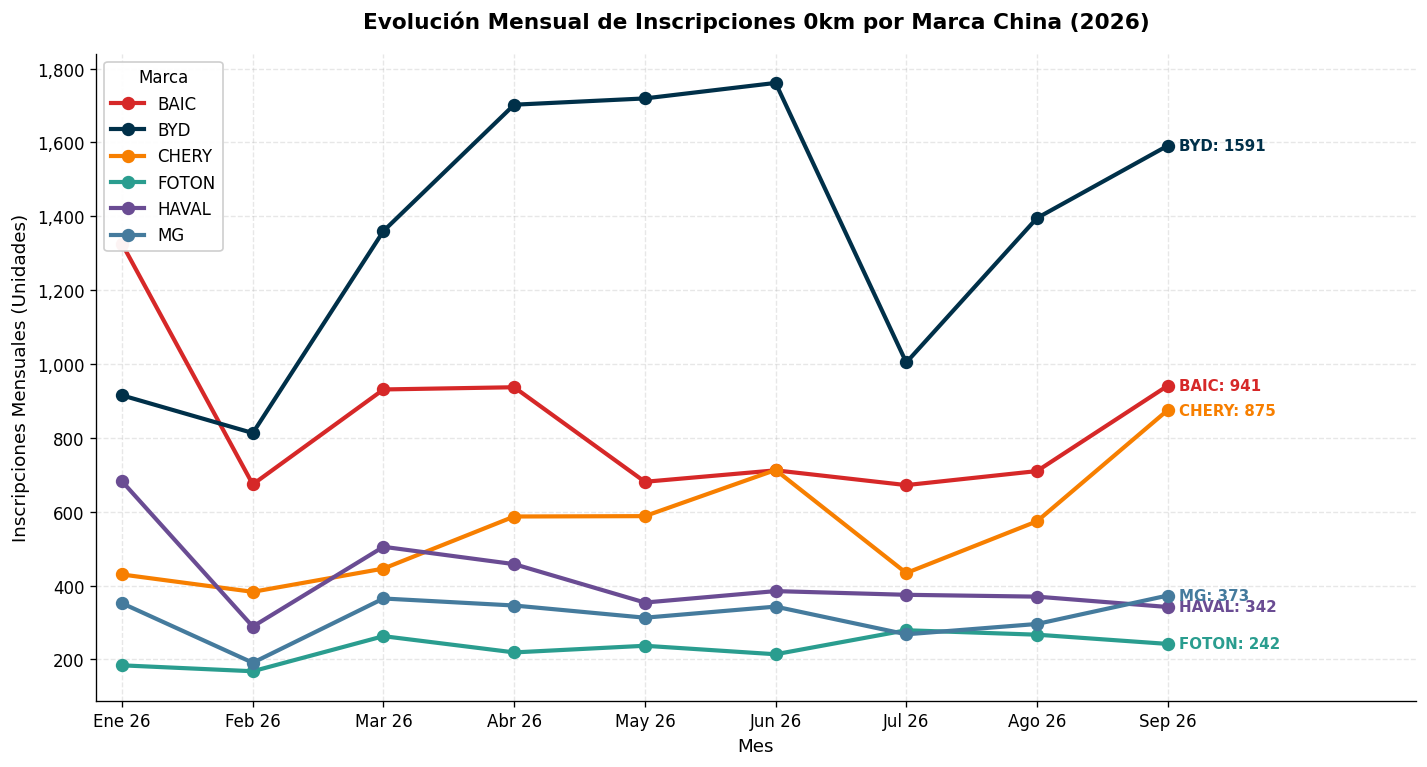


=== TABLA MENSUAL POR MARCA (UNIDADES) ===
automotor_marca_descripcion  BAIC   BYD  CHERY  FOTON  HAVAL   MG
Ene 26                       1325   915    430    184    682  352
Feb 26                        674   813    383    168    289  191
Mar 26                        931  1360    446    263    505  365
Abr 26                        937  1702    587    219    458  346
May 26                        681  1719    588    237    354  313
Jun 26                        712  1761    713    214    385  343
Jul 26                        672  1004    434    279    375  268
Ago 26                        710  1395    574    267    370  296
Sep 26                        941  1591    875    242    342  373


In [71]:
# 5. EVOLUCIÓN MENSUAL POR MARCA
def analizar_carrera_marcas(df: pd.DataFrame, top_k: int = 6):
    df_proc = df.copy()
    marca_norm = df_proc['automotor_marca_descripcion'].astype(str).str.strip().str.upper()
    df_chinos = df_proc[marca_norm.isin(MARCAS_OBJETIVO)].copy()
    
    df_chinos['mes'] = pd.to_datetime(df_chinos['tramite_fecha'], errors='coerce').dt.to_period('M').astype(str)
    
    top_marcas = df_chinos['automotor_marca_descripcion'].str.upper().value_counts().head(top_k).index.tolist()
    
    evol = (
        df_chinos[df_chinos['automotor_marca_descripcion'].str.upper().isin(top_marcas)]
        .groupby(['mes', 'automotor_marca_descripcion'])
        .size()
        .unstack(fill_value=0)
    )
    
    # Nombres amigables para meses
    nombres_meses = {
        '2026-01': 'Ene 26', '2026-02': 'Feb 26', '2026-03': 'Mar 26',
        '2026-04': 'Abr 26', '2026-05': 'May 26', '2026-06': 'Jun 26',
        '2026-07': 'Jul 26', '2026-08': 'Ago 26', '2026-09': 'Sep 26'
    }
    evol.index = [nombres_meses.get(m, m) for m in evol.index]
    
    fig, ax = plt.subplots(figsize=(12, 6.5), dpi=120)
    colores = ['#D62828', '#003049', '#F77F00', '#2A9D8F', '#6A4C93', '#457B9D', '#1D3557']
    
    for col, color in zip(evol.columns, colores):
        ax.plot(evol.index, evol[col], marker='o', linewidth=2.5, markersize=7, label=col, color=color)
        # Anotar el último valor en el gráfico (Sep 26)
        ultimo_val = evol[col].iloc[-1]
        ax.annotate(
            f'{col}: {ultimo_val}',
            xy=(len(evol.index)-1, ultimo_val),
            xytext=(7, 0), textcoords='offset points',
            va='center', fontsize=9, fontweight='bold', color=color
        )
        
    ax.set_title('Evolución Mensual de Inscripciones 0km por Marca China (2026)', fontsize=13, fontweight='bold', pad=15)
    ax.set_ylabel('Inscripciones Mensuales (Unidades)', fontsize=11)
    ax.set_xlabel('Mes', fontsize=11)
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
    ax.set_xlim(-0.2, len(evol.index) + 0.9)
    ax.legend(title='Marca', loc='upper left', frameon=True, facecolor='white', framealpha=0.95)
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    plt.tight_layout()
    plt.show()
    
    print("\n=== TABLA MENSUAL POR MARCA (UNIDADES) ===")
    print(evol)
    return evol

tabla_carrera = analizar_carrera_marcas(df)


## 6. Segmentos de Carrocería: Especialización en SUVs vs Mercado General
Comparamos la matriz de tipos de carrocería (`automotor_tipo_descripcion`) entre las marcas chinas y el mercado automotor tradicional de Argentina.


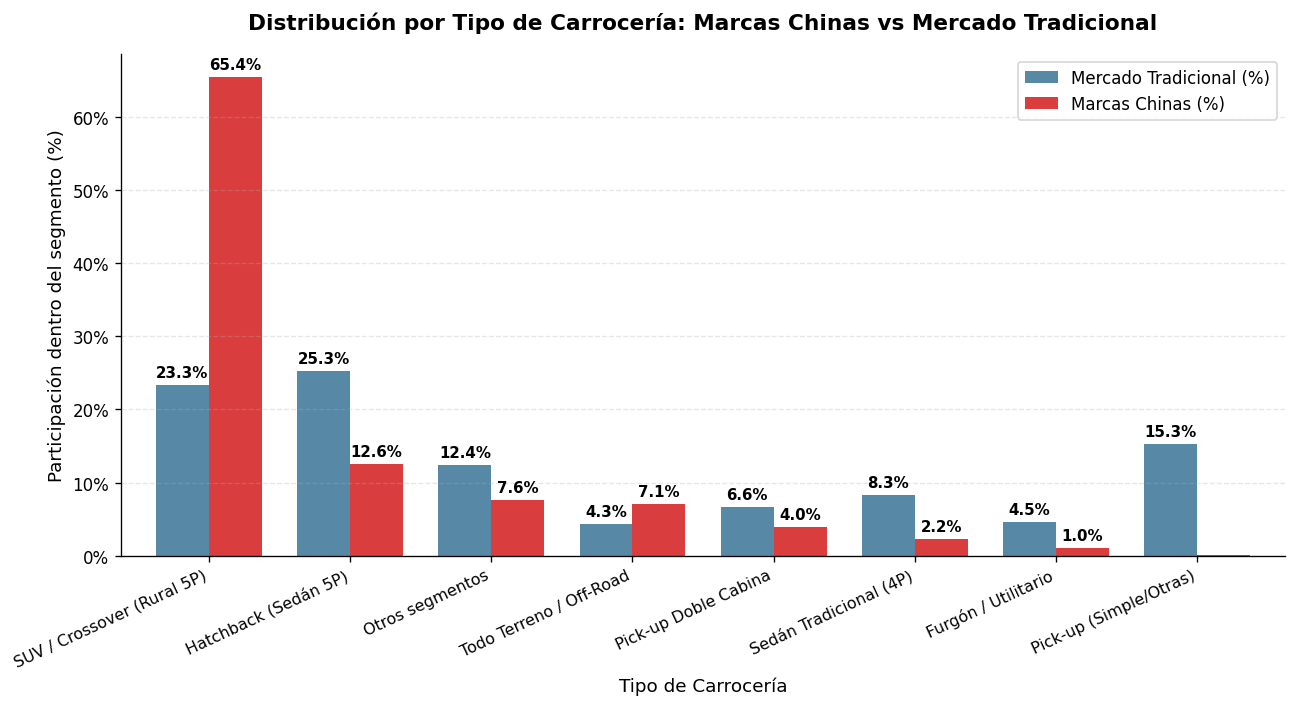


=== COMPARATIVA DE CARROCERÍAS (%) ===
                            Mercado Tradicional (%)  Marcas Chinas (%)
SUV / Crossover (Rural 5P)                    23.34              65.43
Hatchback (Sedán 5P)                          25.28              12.57
Otros segmentos                               12.36               7.65
Todo Terreno / Off-Road                        4.31               7.07
Pick-up Doble Cabina                           6.59               3.97
Sedán Tradicional (4P)                         8.32               2.24
Furgón / Utilitario                            4.54               1.04
Pick-up (Simple/Otras)                        15.25               0.04


In [72]:
# 6. COMPARATIVA DE TIPOS DE VEHÍCULO (CARROCERÍAS)
def analizar_segmentos_carroceria(df: pd.DataFrame):
    df_proc = df.copy()
    marca_norm = df_proc['automotor_marca_descripcion'].astype(str).str.strip().str.upper()
    df_proc['es_chino'] = marca_norm.isin(MARCAS_OBJETIVO)
    
    # Normalizar tipos más frecuentes y agrupar residuales
    tipo_norm = df_proc['automotor_tipo_descripcion'].astype(str).str.strip().str.upper()
    top_tipos = ['RURAL 5 PUERTAS', 'SEDAN 5 PUERTAS', 'PICK-UP', 'SEDAN 4 PUERTAS', 'PICK-UP CABINA DOBLE', 'TODO TERRENO', 'FURGON']
    df_proc['tipo_agrupado'] = np.where(tipo_norm.isin(top_tipos), tipo_norm, 'OTROS')
    
    # Calcular porcentajes relativos
    comp = pd.crosstab(df_proc['tipo_agrupado'], df_proc['es_chino'], normalize='columns') * 100
    comp.columns = ['Mercado Tradicional (%)', 'Marcas Chinas (%)']
    comp = comp.sort_values('Marcas Chinas (%)', ascending=False)
    
    # Etiquetas en lenguaje claro
    nombres_amigables = {
        'RURAL 5 PUERTAS': 'SUV / Crossover (Rural 5P)',
        'SEDAN 5 PUERTAS': 'Hatchback (Sedán 5P)',
        'TODO TERRENO': 'Todo Terreno / Off-Road',
        'PICK-UP CABINA DOBLE': 'Pick-up Doble Cabina',
        'PICK-UP': 'Pick-up (Simple/Otras)',
        'SEDAN 4 PUERTAS': 'Sedán Tradicional (4P)',
        'FURGON': 'Furgón / Utilitario',
        'OTROS': 'Otros segmentos'
    }
    comp.index = [nombres_amigables.get(i, i) for i in comp.index]
    
    # Crear figura y eje con dpi en subplots (evita el AttributeError en pandas plot)
    fig, ax = plt.subplots(figsize=(11, 6), dpi=120)
    comp.plot(kind='bar', ax=ax, color=['#457B9D', '#D62828'], width=0.75, alpha=0.9)
    
    ax.set_title('Distribución por Tipo de Carrocería: Marcas Chinas vs Mercado Tradicional', fontsize=13, fontweight='bold', pad=15)
    ax.set_ylabel('Participación dentro del segmento (%)', fontsize=11)
    ax.set_xlabel('Tipo de Carrocería', fontsize=11)
    ax.set_xticklabels(comp.index, rotation=25, ha='right', fontsize=9.5)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(axis='y', linestyle='--', alpha=0.3)
    ax.legend(frameon=True, facecolor='white')
    
    for p in ax.patches:
        h = p.get_height()
        if h > 1.0:
            ax.annotate(
                f'{h:.1f}%',
                (p.get_x() + p.get_width() / 2., h),
                ha='center', va='bottom', fontsize=9, fontweight='bold', xytext=(0, 3), textcoords='offset points'
            )
            
    plt.tight_layout()
    plt.show()
    
    print("\n=== COMPARATIVA DE CARROCERÍAS (%) ===")
    print(comp.round(2))
    return comp

tabla_carrocerias = analizar_segmentos_carroceria(df)


## 7. Perfil Sociodemográfico del Comprador: Rango Etario y Tipo de Titular
Analizamos quién compra autos chinos en Argentina: distribución por grupos de edad (jóvenes vs adultos vs seniors) y la proporción de ventas a particulares (Personas Físicas) frente a empresas (Personas Jurídicas).


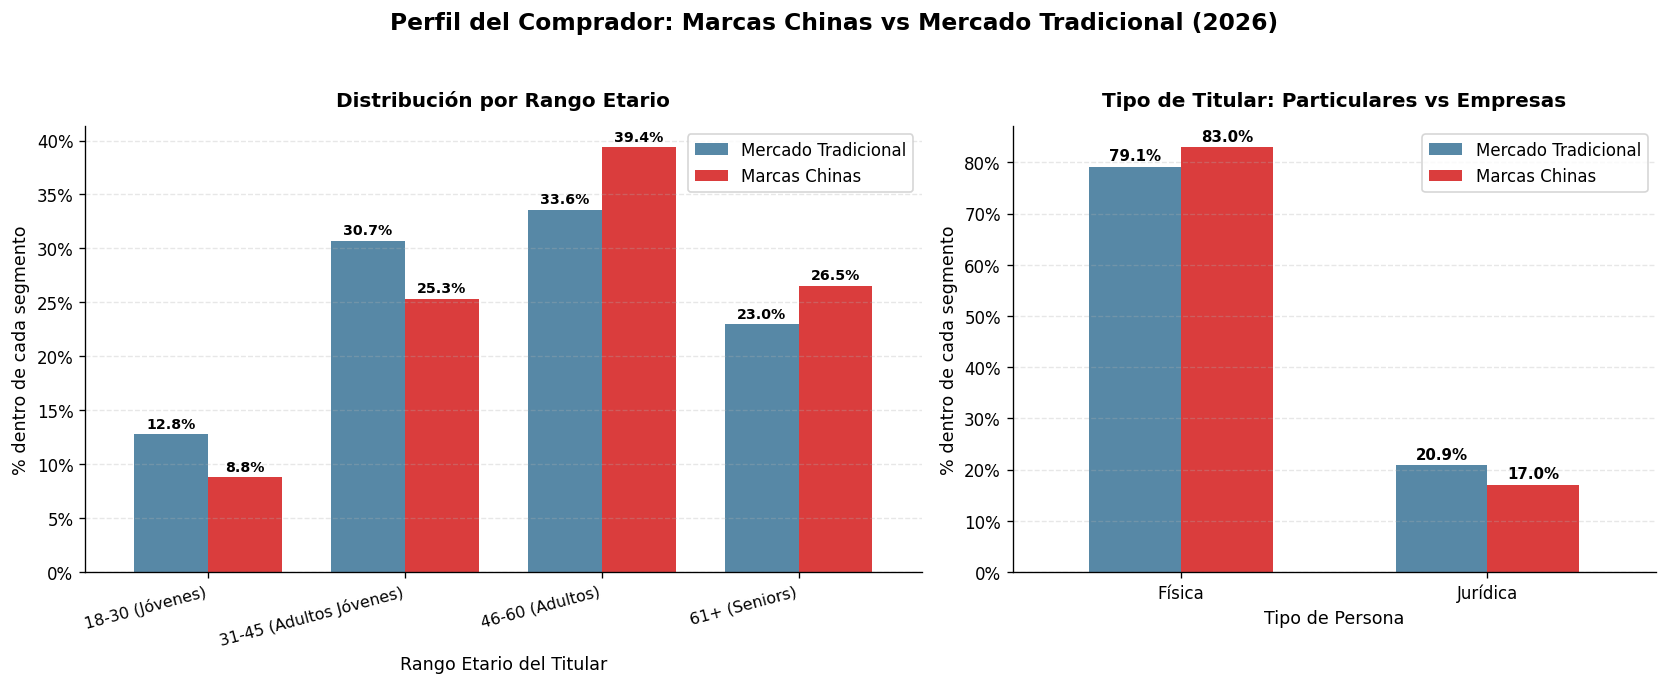


=== SÍNTESIS DE EDAD Y TIPO DE PERSONA ===
• Edad mediana comprador tradicional: 48 años (Media: 48.2 años)
• Edad mediana comprador marcas chinas: 51 años (Media: 50.9 años)
• Participación de Personas Físicas (B2C) en marcas chinas: 83.0% vs 79.1% en el mercado general.


In [73]:
# 7. PERFIL DEL TITULAR: EDAD Y TIPO DE PERSONA
def analizar_perfil_titular(df: pd.DataFrame):
    df_proc = df.copy()
    marca_norm = df_proc['automotor_marca_descripcion'].astype(str).str.strip().str.upper()
    df_proc['es_chino'] = marca_norm.isin(MARCAS_OBJETIVO)
    
    # 1. Rango Etario (Personas Físicas con año de nacimiento válido)
    df_proc['edad'] = 2026 - pd.to_numeric(df_proc['titular_anio_nacimiento'], errors='coerce')
    df_edad = df_proc[(df_proc['edad'] >= 18) & (df_proc['edad'] <= 90)].copy()
    df_edad['rango_etario'] = pd.cut(
        df_edad['edad'],
        bins=[18, 30, 45, 60, 90],
        labels=['18-30 (Jóvenes)', '31-45 (Adultos Jóvenes)', '46-60 (Adultos)', '61+ (Seniors)']
    )
    comp_edad = pd.crosstab(df_edad['rango_etario'], df_edad['es_chino'], normalize='columns') * 100
    comp_edad.columns = ['Mercado Tradicional', 'Marcas Chinas']
    
    # 2. Tipo de Persona (Física vs Jurídica)
    tipo_p = pd.crosstab(df_proc['titular_tipo_persona'].astype(str).str.strip(), df_proc['es_chino'], normalize='columns') * 100
    tipo_p.columns = ['Mercado Tradicional', 'Marcas Chinas']
    
    # Gráficos combinados en 2 paneles (Subplots)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), dpi=120, gridspec_kw={'width_ratios': [1.3, 1]})
    
    # Panel 1: Rango Etario
    comp_edad.plot(kind='bar', ax=ax1, color=['#457B9D', '#D62828'], width=0.75, alpha=0.9)
    ax1.set_title('Distribución por Rango Etario', fontsize=12, fontweight='bold', pad=12)
    ax1.set_ylabel('% dentro de cada segmento', fontsize=10.5)
    ax1.set_xlabel('Rango Etario del Titular', fontsize=10.5)
    ax1.set_xticklabels(comp_edad.index, rotation=15, ha='right', fontsize=9.5)
    ax1.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    ax1.grid(axis='y', linestyle='--', alpha=0.3)
    ax1.legend(frameon=True, facecolor='white')
    
    for p in ax1.patches:
        h = p.get_height()
        if h > 0:
            ax1.annotate(f'{h:.1f}%', (p.get_x() + p.get_width() / 2., h),
                         ha='center', va='bottom', fontsize=8.5, fontweight='bold', xytext=(0, 2), textcoords='offset points')
                         
    # Panel 2: Tipo de Persona (Física vs Jurídica)
    tipo_p.plot(kind='bar', ax=ax2, color=['#457B9D', '#D62828'], width=0.6, alpha=0.9)
    ax2.set_title('Tipo de Titular: Particulares vs Empresas', fontsize=12, fontweight='bold', pad=12)
    ax2.set_ylabel('% dentro de cada segmento', fontsize=10.5)
    ax2.set_xlabel('Tipo de Persona', fontsize=10.5)
    ax2.set_xticklabels(tipo_p.index, rotation=0, fontsize=10)
    ax2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    ax2.grid(axis='y', linestyle='--', alpha=0.3)
    ax2.legend(frameon=True, facecolor='white')
    
    for p in ax2.patches:
        h = p.get_height()
        if h > 0:
            ax2.annotate(f'{h:.1f}%', (p.get_x() + p.get_width() / 2., h),
                         ha='center', va='bottom', fontsize=9, fontweight='bold', xytext=(0, 2), textcoords='offset points')
                         
    plt.suptitle('Perfil del Comprador: Marcas Chinas vs Mercado Tradicional (2026)', fontsize=14, fontweight='bold', y=1.03)
    plt.tight_layout()
    plt.show()
    
    edad_ch = df_edad[df_edad['es_chino']]['edad']
    edad_trad = df_edad[~df_edad['es_chino']]['edad']
    print("\n=== SÍNTESIS DE EDAD Y TIPO DE PERSONA ===")
    print(f"• Edad mediana comprador tradicional: {edad_trad.median():.0f} años (Media: {edad_trad.mean():.1f} años)")
    print(f"• Edad mediana comprador marcas chinas: {edad_ch.median():.0f} años (Media: {edad_ch.mean():.1f} años)")
    print(f"• Participación de Personas Físicas (B2C) en marcas chinas: {tipo_p.loc['Física', 'Marcas Chinas']:.1f}% vs {tipo_p.loc['Física', 'Mercado Tradicional']:.1f}% en el mercado general.")
    return comp_edad, tipo_p

comp_edad, comp_tipo = analizar_perfil_titular(df)


## 8. Elasticidad Geográfica y Canales de Comercialización (Registros Seccionales)
Profundizamos el análisis territorial cruzando el código de registro (`registro_seccional_codigo`) para identificar la **concentración de la red comercial** de marcas chinas frente al mercado tradicional.

### Preguntas clave respondidas:
1. **¿Qué tan concentrada está la red de ventas?** Evaluación de curvas acumuladas tipo Pareto/Lorenz: ¿cuántos registros explican el 50% y el 80% de los patentamientos chinos vs tradicionales?
2. **¿Cuáles son los polos y corredores clave?** Top 10 registros por volumen y registros con mayor tasa de penetración (>50% de cuota de mercado local).

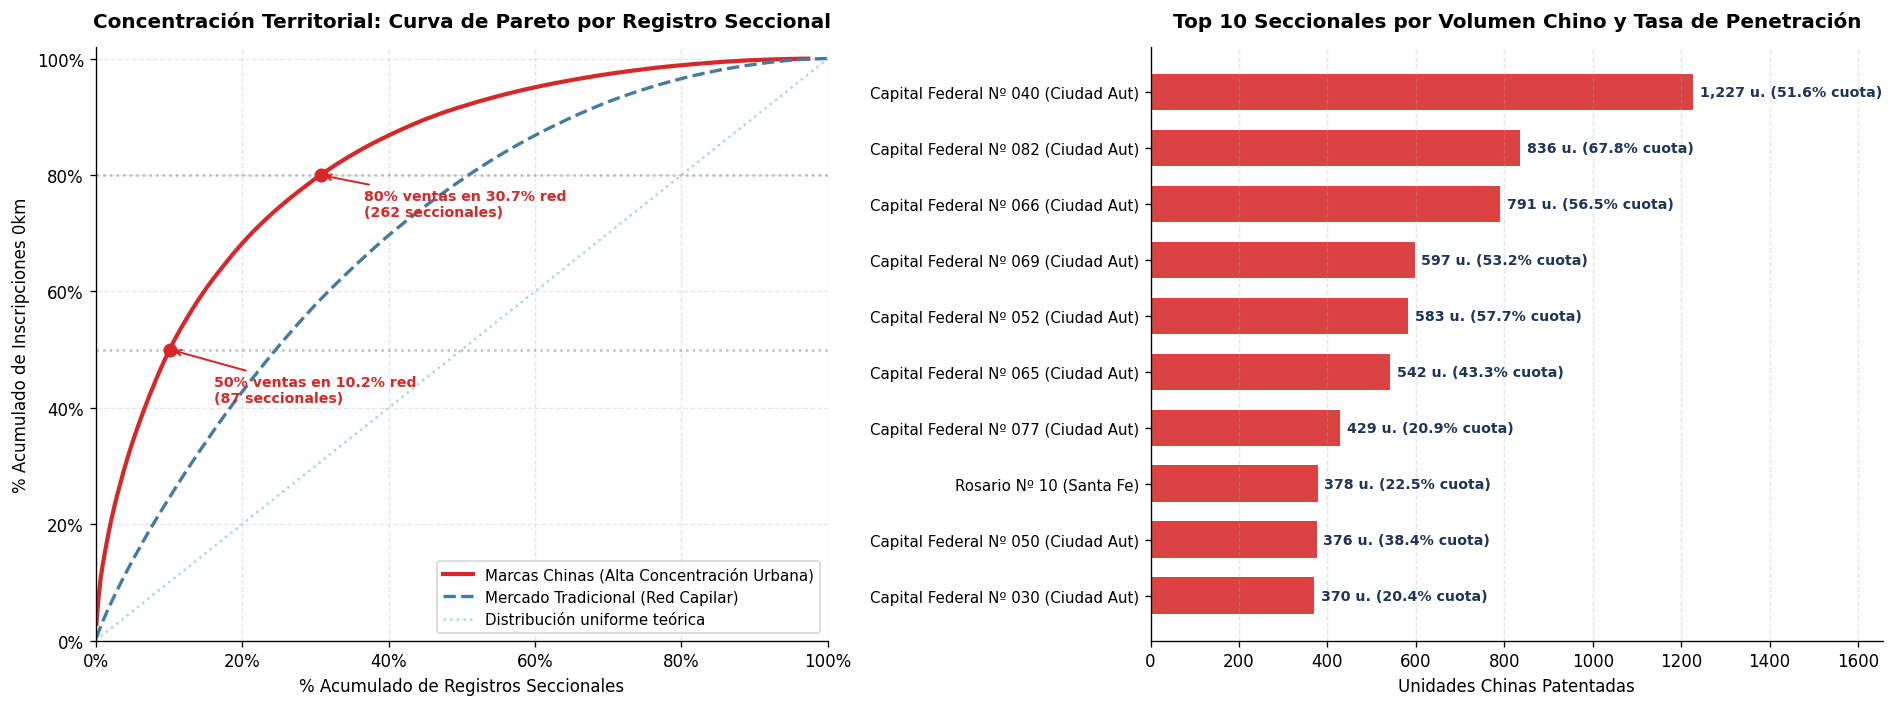

=== DIAGNÓSTICO DE ELASTICIDAD Y CONCENTRACIÓN SECCIONAL ===
Red total: 853 registros seccionales en Argentina
• 50% de patentamientos chinos: Concentrado en 87 registros (10.2% de la red)
• 50% mercado tradicional: Distribuido en 210 registros (24.6% de la red)
• 80% de patentamientos chinos: Concentrado en 262 registros (30.7% de la red)
• 80% mercado tradicional: Distribuido en 435 registros (51.0% de la red)


In [74]:
# 8. CONCENTRACIÓN COMERCIAL Y RED DE REGISTROS SECCIONALES (PARETO)
def analizar_concentracion_seccionales(df: pd.DataFrame):
    df_proc = df.copy()
    marca_norm = df_proc['automotor_marca_descripcion'].astype(str).str.strip().str.upper()
    df_proc['es_chino'] = marca_norm.isin(MARCAS_OBJETIVO)
    
    # 1. Agrupación y métricas por registro seccional
    secc = df_proc.groupby(['registro_seccional_codigo', 'registro_seccional_descripcion', 'registro_seccional_provincia']).agg(
        total_inscripciones=('es_chino', 'count'),
        chinos_qty=('es_chino', 'sum')
    ).reset_index()
    secc['trad_qty'] = secc['total_inscripciones'] - secc['chinos_qty']
    secc['pct_chino'] = (secc['chinos_qty'] / secc['total_inscripciones']) * 100
    
    total_red = len(secc)
    
    # 2. Curvas de concentración acumulada (Pareto)
    # Marcas chinas
    chinos_sorted = secc[secc['chinos_qty'] > 0].sort_values('chinos_qty', ascending=False).copy()
    chinos_sorted['pct_red_acum'] = (np.arange(1, len(chinos_sorted) + 1) / total_red) * 100
    chinos_sorted['pct_ventas_acum'] = (chinos_sorted['chinos_qty'].cumsum() / chinos_sorted['chinos_qty'].sum()) * 100
    
    # Mercado tradicional
    trad_sorted = secc[secc['trad_qty'] > 0].sort_values('trad_qty', ascending=False).copy()
    trad_sorted['pct_red_acum'] = (np.arange(1, len(trad_sorted) + 1) / total_red) * 100
    trad_sorted['pct_ventas_acum'] = (trad_sorted['trad_qty'].cumsum() / trad_sorted['trad_qty'].sum()) * 100
    
    # Puntos de corte clave (50% y 80%)
    n_50_ch = (chinos_sorted['pct_ventas_acum'] <= 50).sum() + 1
    pct_red_50_ch = (n_50_ch / total_red) * 100
    n_80_ch = (chinos_sorted['pct_ventas_acum'] <= 80).sum() + 1
    pct_red_80_ch = (n_80_ch / total_red) * 100
    
    n_50_tr = (trad_sorted['pct_ventas_acum'] <= 50).sum() + 1
    pct_red_50_tr = (n_50_tr / total_red) * 100
    n_80_tr = (trad_sorted['pct_ventas_acum'] <= 80).sum() + 1
    pct_red_80_tr = (n_80_tr / total_red) * 100
    
    # 3. Visualización: Doble Panel (Curva Pareto + Top Registros)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), dpi=120)
    
    # Panel Izquierdo: Curva de Concentración
    ax1.plot(chinos_sorted['pct_red_acum'], chinos_sorted['pct_ventas_acum'], 
             color='#D62828', linewidth=2.5, label='Marcas Chinas (Alta Concentración Urbana)')
    ax1.plot(trad_sorted['pct_red_acum'], trad_sorted['pct_ventas_acum'], 
             color='#457B9D', linewidth=2, linestyle='--', label='Mercado Tradicional (Red Capilar)')
    ax1.plot([0, 100], [0, 100], color='#A8DADC', linestyle=':', label='Distribución uniforme teórica')
    
    ax1.axhline(50, color='gray', linestyle=':', alpha=0.5)
    ax1.axhline(80, color='gray', linestyle=':', alpha=0.5)
    ax1.scatter([pct_red_50_ch, pct_red_80_ch], [50, 80], color='#D62828', s=55, zorder=5)
    
    ax1.annotate(f'50% ventas en {pct_red_50_ch:.1f}% red\n({n_50_ch} seccionales)', 
                 xy=(pct_red_50_ch, 50), xytext=(pct_red_50_ch + 6, 41),
                 arrowprops=dict(arrowstyle='->', color='#D62828', lw=1.2), fontsize=8.5, fontweight='bold', color='#D62828')
    ax1.annotate(f'80% ventas en {pct_red_80_ch:.1f}% red\n({n_80_ch} seccionales)', 
                 xy=(pct_red_80_ch, 80), xytext=(pct_red_80_ch + 6, 73),
                 arrowprops=dict(arrowstyle='->', color='#D62828', lw=1.2), fontsize=8.5, fontweight='bold', color='#D62828')
    
    ax1.set_title('Concentración Territorial: Curva de Pareto por Registro Seccional', fontsize=12, fontweight='bold', pad=12)
    ax1.set_xlabel('% Acumulado de Registros Seccionales', fontsize=10)
    ax1.set_ylabel('% Acumulado de Inscripciones 0km', fontsize=10)
    ax1.set_xlim(0, 100)
    ax1.set_ylim(0, 102)
    ax1.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax1.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax1.grid(True, linestyle='--', alpha=0.3)
    ax1.legend(loc='lower right', frameon=True, facecolor='white', fontsize=9)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    
    # Panel Derecho: Top 10 Registros Seccionales en Volumen Chino
    top_10 = secc.sort_values('chinos_qty', ascending=False).head(10).copy()
    top_10['etiqueta'] = top_10['registro_seccional_descripcion'].str.title() + ' (' + top_10['registro_seccional_provincia'].astype(str).str.slice(0, 10) + ')'
    top_10 = top_10.sort_values('chinos_qty', ascending=True)
    
    y_pos = np.arange(len(top_10))
    bars = ax2.barh(y_pos, top_10['chinos_qty'], color='#D62828', height=0.65, alpha=0.88)
    ax2.set_yticks(y_pos)
    ax2.set_yticklabels(top_10['etiqueta'], fontsize=9)
    ax2.set_title('Top 10 Seccionales por Volumen Chino y Tasa de Penetración', fontsize=12, fontweight='bold', pad=12)
    ax2.set_xlabel('Unidades Chinas Patentadas', fontsize=10)
    ax2.grid(axis='x', linestyle='--', alpha=0.3)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    
    for bar, (_, row) in zip(bars, top_10.iterrows()):
        w = bar.get_width()
        ax2.text(w + 15, bar.get_y() + bar.get_height()/2, 
                 f"{int(w):,} u. ({row['pct_chino']:.1f}% cuota)", 
                 va='center', fontsize=8.5, fontweight='bold', color='#1D3557')
    ax2.set_xlim(0, top_10['chinos_qty'].max() * 1.35)
    
    plt.tight_layout()
    plt.show()
    
    print(f"=== DIAGNÓSTICO DE ELASTICIDAD Y CONCENTRACIÓN SECCIONAL ===")
    print(f"Red total: {total_red} registros seccionales en Argentina")
    print(f"• 50% de patentamientos chinos: Concentrado en {n_50_ch} registros ({pct_red_50_ch:.1f}% de la red)")
    print(f"• 50% mercado tradicional: Distribuido en {n_50_tr} registros ({pct_red_50_tr:.1f}% de la red)")
    print(f"• 80% de patentamientos chinos: Concentrado en {n_80_ch} registros ({pct_red_80_ch:.1f}% de la red)")
    print(f"• 80% mercado tradicional: Distribuido en {n_80_tr} registros ({pct_red_80_tr:.1f}% de la red)")
    
    return secc

tabla_seccionales = analizar_concentracion_seccionales(df)

## 9. Detección Rigurosa de Anomalías, Outliers y Estructura MNAR
Evaluamos la integridad y calidad de los datos del dataset oficial de DNRPA:
1. **Patrones de Valores Faltantes No Aleatorios (MNAR)**: Determinamos si las columnas de perfil demográfico (`titular_genero`, `titular_pais_nacimiento`, `titular_anio_nacimiento`) presentan ausencias estructurales por el tipo de titular (Persona Física vs. Persona Jurídica).
2. **Detección y Aislamiento de Outliers**: Limpieza de cadenas de texto con espacios en blanco, coerción a valores numéricos enteros, y auditoría de edades atípicas (edad = 0 y menores de 18 años).

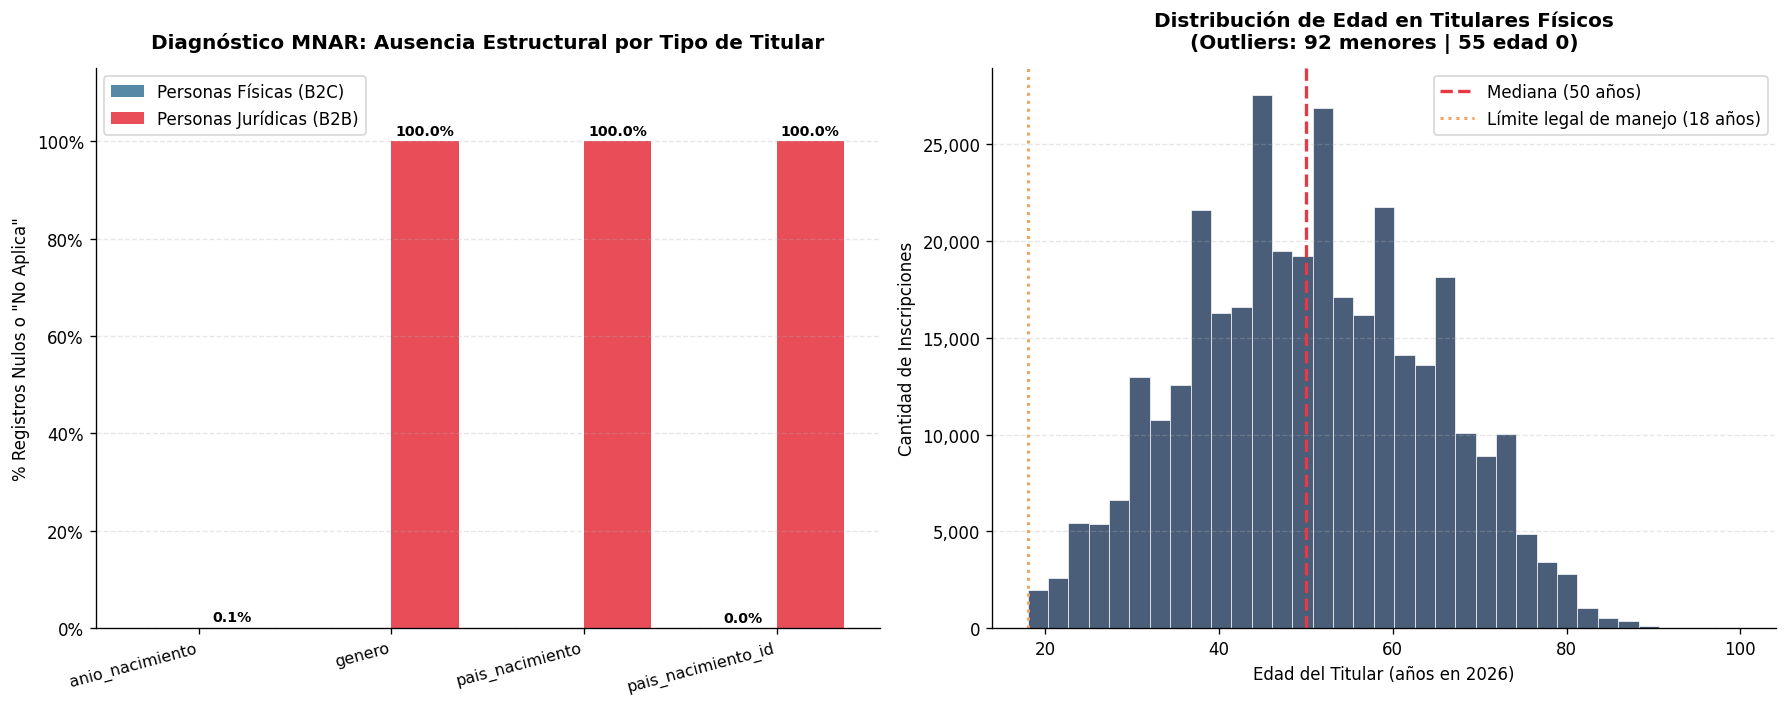


=== AUDITORÍA DE CALIDAD Y OUTLIERS DE EDAD ===
                                 Categoría  Casos  % sobre Físicas                           Impacto
          Total Titulares Personas Físicas 348942       100.000000                  Base poblacional
Titulares Físicos con Edad Válida (18-100) 348795        99.957873                  Datos confiables
      Outlier: Menores de 18 años (1 a 17)     92         0.026365           Condominios/Error carga
   Outlier: Edad = 0 (año nacimiento 2026)     55         0.015762            Default administrativo
Missing: Espacios en blanco / Nulos en año      0         0.000000 Cero en físicas (89 en jurídicas)


In [75]:
# 9. AUDITORÍA DE CALIDAD, PATRONES MNAR Y ANOMALÍAS DE DATOS
def analizar_calidad_outliers(df: pd.DataFrame):
    df_proc = df.copy()
    
    # 1. Análisis de Ausencia Estructural MNAR (Física vs Jurídica)
    tipo_persona = df_proc['titular_tipo_persona'].astype(str).str.strip().str.capitalize()
    demo_cols = ['titular_anio_nacimiento', 'titular_genero', 'titular_pais_nacimiento', 'titular_pais_nacimiento_id']
    
    mnar_data = []
    for col in demo_cols:
        val_series = df_proc[col].astype(str).str.strip()
        is_missing_or_na = val_series.isin(['', 'nan', 'None', 'No aplica']) | df_proc[col].isnull()
        
        pct_fisica = (is_missing_or_na[tipo_persona == 'Física'].mean()) * 100
        pct_juridica = (is_missing_or_na[tipo_persona == 'Jurídica'].mean()) * 100
        mnar_data.append({
            'Campo': col.replace('titular_', ''),
            'Personas Físicas (% Nulo/NA)': pct_fisica,
            'Personas Jurídicas (% Nulo/NA)': pct_juridica
        })
    df_mnar = pd.DataFrame(mnar_data)
    
    # 2. Outliers y valores atípicos en Personas Físicas
    df_fisica = df_proc[tipo_persona == 'Física'].copy()
    anio_limpio = pd.to_numeric(df_fisica['titular_anio_nacimiento'].astype(str).str.strip(), errors='coerce')
    edades = 2026 - anio_limpio
    
    total_fisicas = len(df_fisica)
    nulos_anio = anio_limpio.isnull().sum()
    edad_cero = (edades == 0).sum()
    edad_menor_18 = ((edades > 0) & (edades < 18)).sum()
    edad_valida = ((edades >= 18) & (edades <= 100)).sum()
    edad_mayor_100 = (edades > 100).sum()
    
    # 3. Visualización: Diagnóstico MNAR e Histograma de Outliers
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), dpi=120)
    
    # Subplot 1: Patrón MNAR
    x = np.arange(len(df_mnar))
    width = 0.35
    b1 = ax1.bar(x - width/2, df_mnar['Personas Físicas (% Nulo/NA)'], width, label='Personas Físicas (B2C)', color='#457B9D', alpha=0.9)
    b2 = ax1.bar(x + width/2, df_mnar['Personas Jurídicas (% Nulo/NA)'], width, label='Personas Jurídicas (B2B)', color='#E63946', alpha=0.9)
    
    ax1.set_title('Diagnóstico MNAR: Ausencia Estructural por Tipo de Titular', fontsize=12, fontweight='bold', pad=12)
    ax1.set_ylabel('% Registros Nulos o "No Aplica"', fontsize=10)
    ax1.set_xticks(x)
    ax1.set_xticklabels(df_mnar['Campo'], rotation=15, ha='right', fontsize=9.5)
    ax1.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax1.set_ylim(0, 115)
    ax1.grid(axis='y', linestyle='--', alpha=0.3)
    ax1.legend(frameon=True, facecolor='white', loc='upper left')
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    
    for rects in [b1, b2]:
        for rect in rects:
            h = rect.get_height()
            if h > 0:
                ax1.annotate(f'{h:.1f}%', (rect.get_x() + rect.get_width() / 2., h),
                             ha='center', va='bottom', fontsize=8.5, fontweight='bold', xytext=(0, 2), textcoords='offset points')
                
    # Subplot 2: Distribución de Edad y Outliers
    edades_validas = edades[(edades >= 18) & (edades <= 100)]
    ax2.hist(edades_validas, bins=35, color='#1D3557', alpha=0.8, edgecolor='white', linewidth=0.5)
    
    mediana = edades_validas.median()
    ax2.axvline(mediana, color='#E63946', linestyle='--', linewidth=2, label=f'Mediana ({mediana:.0f} años)')
    ax2.axvline(18, color='#F4A261', linestyle=':', linewidth=1.8, label='Límite legal de manejo (18 años)')
    
    ax2.set_title(f'Distribución de Edad en Titulares Físicos\n(Outliers: {edad_menor_18} menores | {edad_cero} edad 0)', 
                  fontsize=12, fontweight='bold', pad=12)
    ax2.set_xlabel('Edad del Titular (años en 2026)', fontsize=10)
    ax2.set_ylabel('Cantidad de Inscripciones', fontsize=10)
    ax2.yaxis.set_major_formatter(mtick.FuncFormatter(lambda y, _: f'{int(y):,}'))
    ax2.grid(axis='y', linestyle='--', alpha=0.3)
    ax2.legend(frameon=True, facecolor='white', loc='upper right')
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    
    plt.tight_layout()
    plt.show()
    
    # 4. Tabla de Auditoría
    auditoria = pd.DataFrame([
        {'Categoría': 'Total Titulares Personas Físicas', 'Casos': total_fisicas, '% sobre Físicas': 100.0, 'Impacto': 'Base poblacional'},
        {'Categoría': 'Titulares Físicos con Edad Válida (18-100)', 'Casos': edad_valida, '% sobre Físicas': (edad_valida/total_fisicas)*100, 'Impacto': 'Datos confiables'},
        {'Categoría': 'Outlier: Menores de 18 años (1 a 17)', 'Casos': edad_menor_18, '% sobre Físicas': (edad_menor_18/total_fisicas)*100, 'Impacto': 'Condominios/Error carga'},
        {'Categoría': 'Outlier: Edad = 0 (año nacimiento 2026)', 'Casos': edad_cero, '% sobre Físicas': (edad_cero/total_fisicas)*100, 'Impacto': 'Default administrativo'},
        {'Categoría': 'Missing: Espacios en blanco / Nulos en año', 'Casos': nulos_anio, '% sobre Físicas': (nulos_anio/total_fisicas)*100, 'Impacto': 'Cero en físicas (89 en jurídicas)'},
    ])
    
    print("\n=== AUDITORÍA DE CALIDAD Y OUTLIERS DE EDAD ===")
    print(auditoria.to_string(index=False))
    
    return df_mnar, auditoria

df_mnar, tabla_auditoria = analizar_calidad_outliers(df)